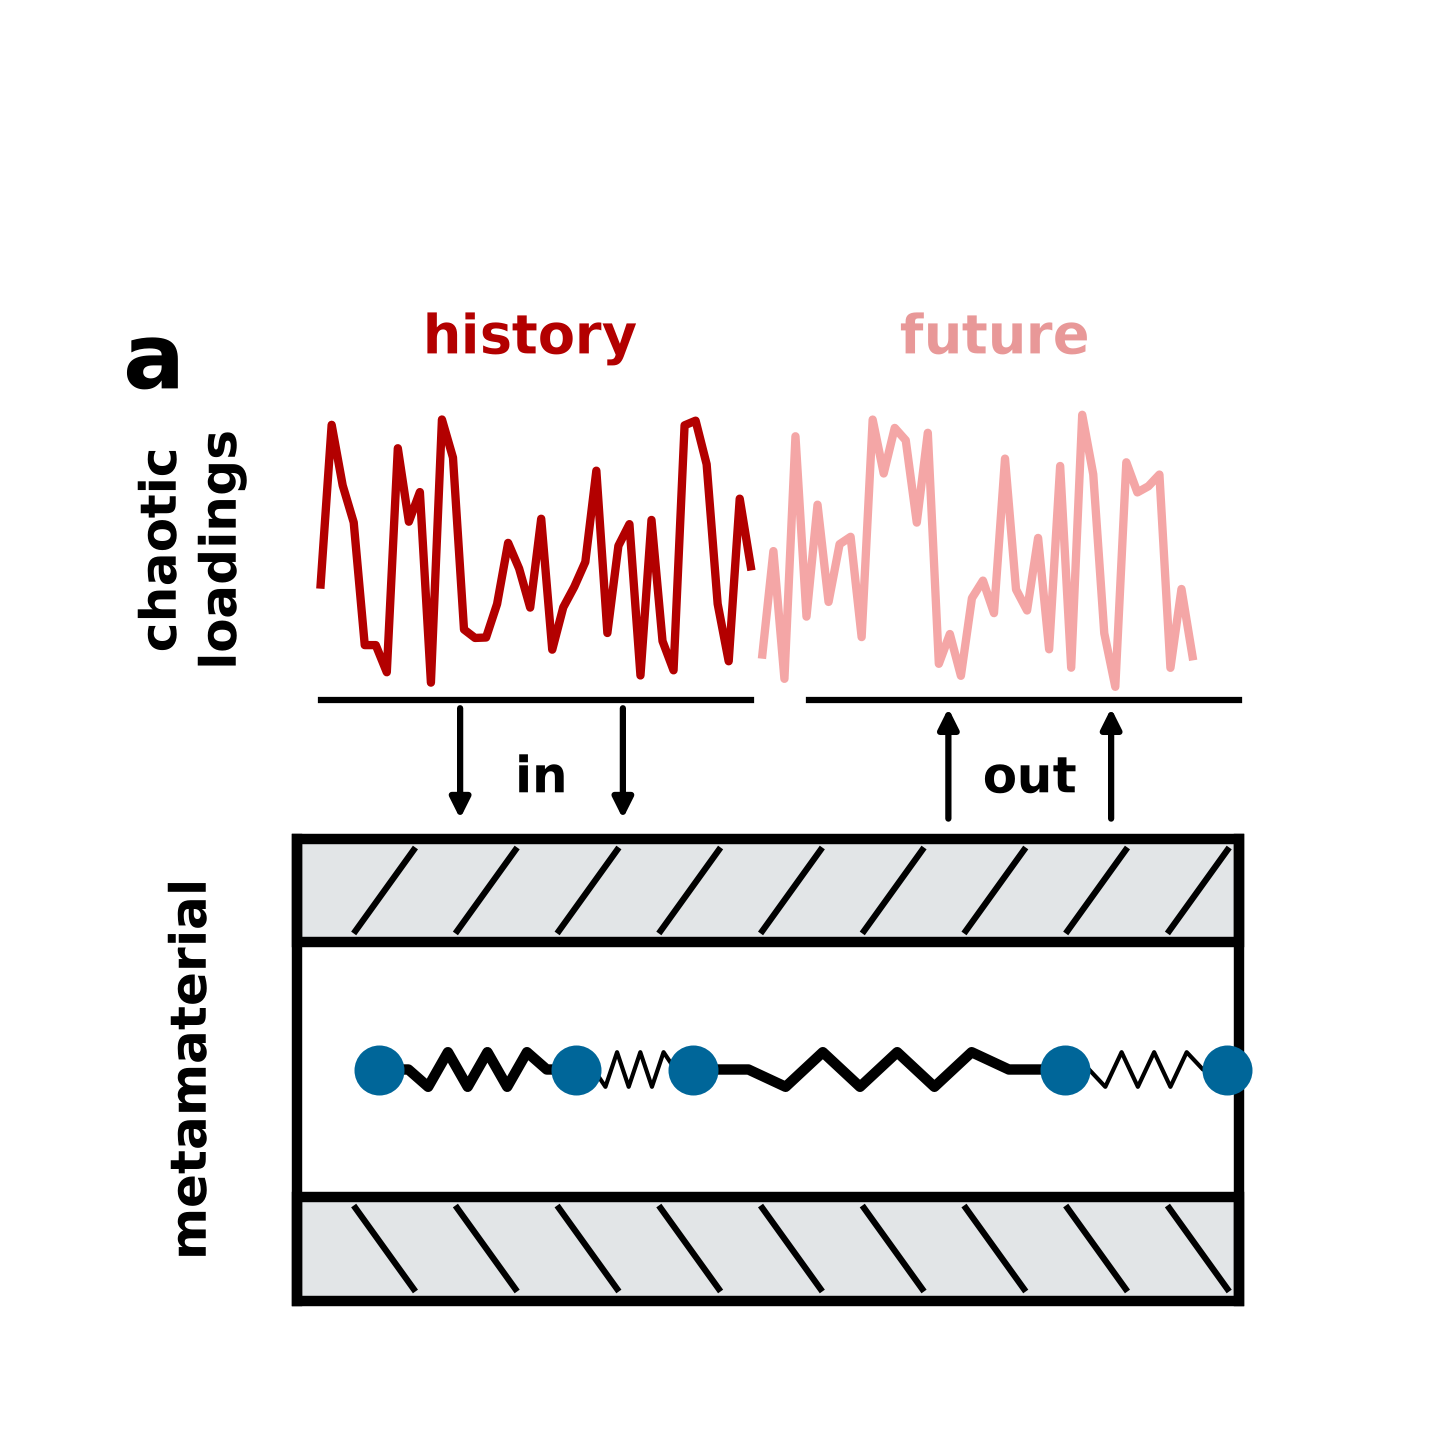

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.1, 1.1)
ax.axis("off")


# Helper function to generate a spring path between two points
def get_spring(p1, p2, nodes=10, width=0.03):
    p1, p2 = np.array(p1), np.array(p2)
    dist = np.linalg.norm(p2 - p1)
    direction = (p2 - p1) / dist
    normal = np.array([-direction[1], direction[0]])

    # Linear lead-in and lead-out
    lead_in = 0.15 * dist
    lead_out = 0.15 * dist
    spring_len = dist - lead_in - lead_out

    t = np.linspace(0, spring_len, nodes)
    offsets = np.sin(np.pi * np.arange(nodes)) * 0 + width * ((-1) ** np.arange(nodes))
    offsets[0] = 0
    offsets[-1] = 0

    pts = [p1, p1 + direction * lead_in]
    for s_t, off in zip(t, offsets):
        pts.append(p1 + direction * (lead_in + s_t) + normal * off)
    pts.append(p2 - direction * lead_out)
    pts.append(p2)
    return np.array(pts)


# 1. Top Signals (History & Future)
np.random.seed(42)
x_hist = np.linspace(0.15, 0.52, 40)
y_hist = 0.65 + np.random.uniform(-0.12, 0.12, len(x_hist))
x_fut = np.linspace(0.53, 0.90, 40)
y_fut = 0.65 + np.random.uniform(-0.12, 0.12, len(x_fut))

ax.plot(x_hist, y_hist, color="#b30000", lw=2)
ax.plot(x_fut, y_fut, color="#f4a6a6", lw=2)
ax.plot([0.15, 0.52], [0.52, 0.52], color="black", lw=1.5)
ax.plot([0.57, 0.94], [0.52, 0.52], color="black", lw=1.5)

ax.text(0.33, 0.82, "history", color="#b30000", fontsize=13, weight="bold", ha="center")
ax.text(0.73, 0.82, "future", color="#e89898", fontsize=13, weight="bold", ha="center")

# 2. Arrows (in / out)
arrow_kw = dict(arrowstyle="-|>", lw=1.5, mutation_scale=10, color="black")
ax.annotate("", xy=(0.27, 0.41), xytext=(0.27, 0.52), arrowprops=arrow_kw)
ax.annotate("", xy=(0.41, 0.41), xytext=(0.41, 0.52), arrowprops=arrow_kw)
ax.text(0.34, 0.44, "in", fontsize=12, weight="bold", ha="center")

ax.annotate("", xy=(0.69, 0.52), xytext=(0.69, 0.41), arrowprops=arrow_kw)
ax.annotate("", xy=(0.83, 0.52), xytext=(0.83, 0.41), arrowprops=arrow_kw)
ax.text(0.76, 0.44, "out", fontsize=12, weight="bold", ha="center")

# 3. Metamaterial Plates
plate_top = patches.Rectangle(
    (0.13, 0.31), 0.81, 0.09, facecolor="#e2e5e7", edgecolor="black", lw=2.5
)
plate_bot = patches.Rectangle(
    (0.13, 0.00), 0.81, 0.09, facecolor="#e2e5e7", edgecolor="black", lw=2.5
)
ax.add_patch(plate_top)
ax.add_patch(plate_bot)

for x_offset in np.linspace(0.18, 0.88, 9):
    ax.plot([x_offset, x_offset + 0.05], [0.32, 0.39], color="black", lw=1.5)
    ax.plot([x_offset, x_offset + 0.05], [0.08, 0.01], color="black", lw=1.5)

# 4. Metamaterial Inner Frame & Nodes
ax.plot([0.13, 0.13], [0.00, 0.40], color="black", lw=2.5)
ax.plot([0.94, 0.94], [0.00, 0.40], color="black", lw=2.5)

node_xs = [0.20, 0.37, 0.47, 0.79, 0.93]
node_y = 0.20
for x in node_xs:
    ax.plot(x, node_y, "o", color="#006699", markersize=11, zorder=5)

# Draw springs between nodes
for i in range(len(node_xs) - 1):
    p_pts = get_spring(
        (node_xs[i], node_y), (node_xs[i + 1], node_y), nodes=8, width=0.015
    )
    lw = 2.5 if i % 2 == 0 else 1.0
    ax.plot(p_pts[:, 0], p_pts[:, 1], color="black", lw=lw, zorder=3)

# 5. Side Labels
ax.text(-0.02, 0.85, "a", fontsize=22, weight="bold", va="top")
ax.text(
    0.04,
    0.65,
    "chaotic\nloadings",
    fontsize=12,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)
ax.text(
    0.04,
    0.20,
    "metamaterial",
    fontsize=12,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)

# Save directly as SVG or PNG
# plt.savefig("metamaterial_diagram.svg", bbox_inches="tight")
# plt.savefig("metamaterial_diagram.png", bbox_inches="tight", dpi=300)
plt.show()

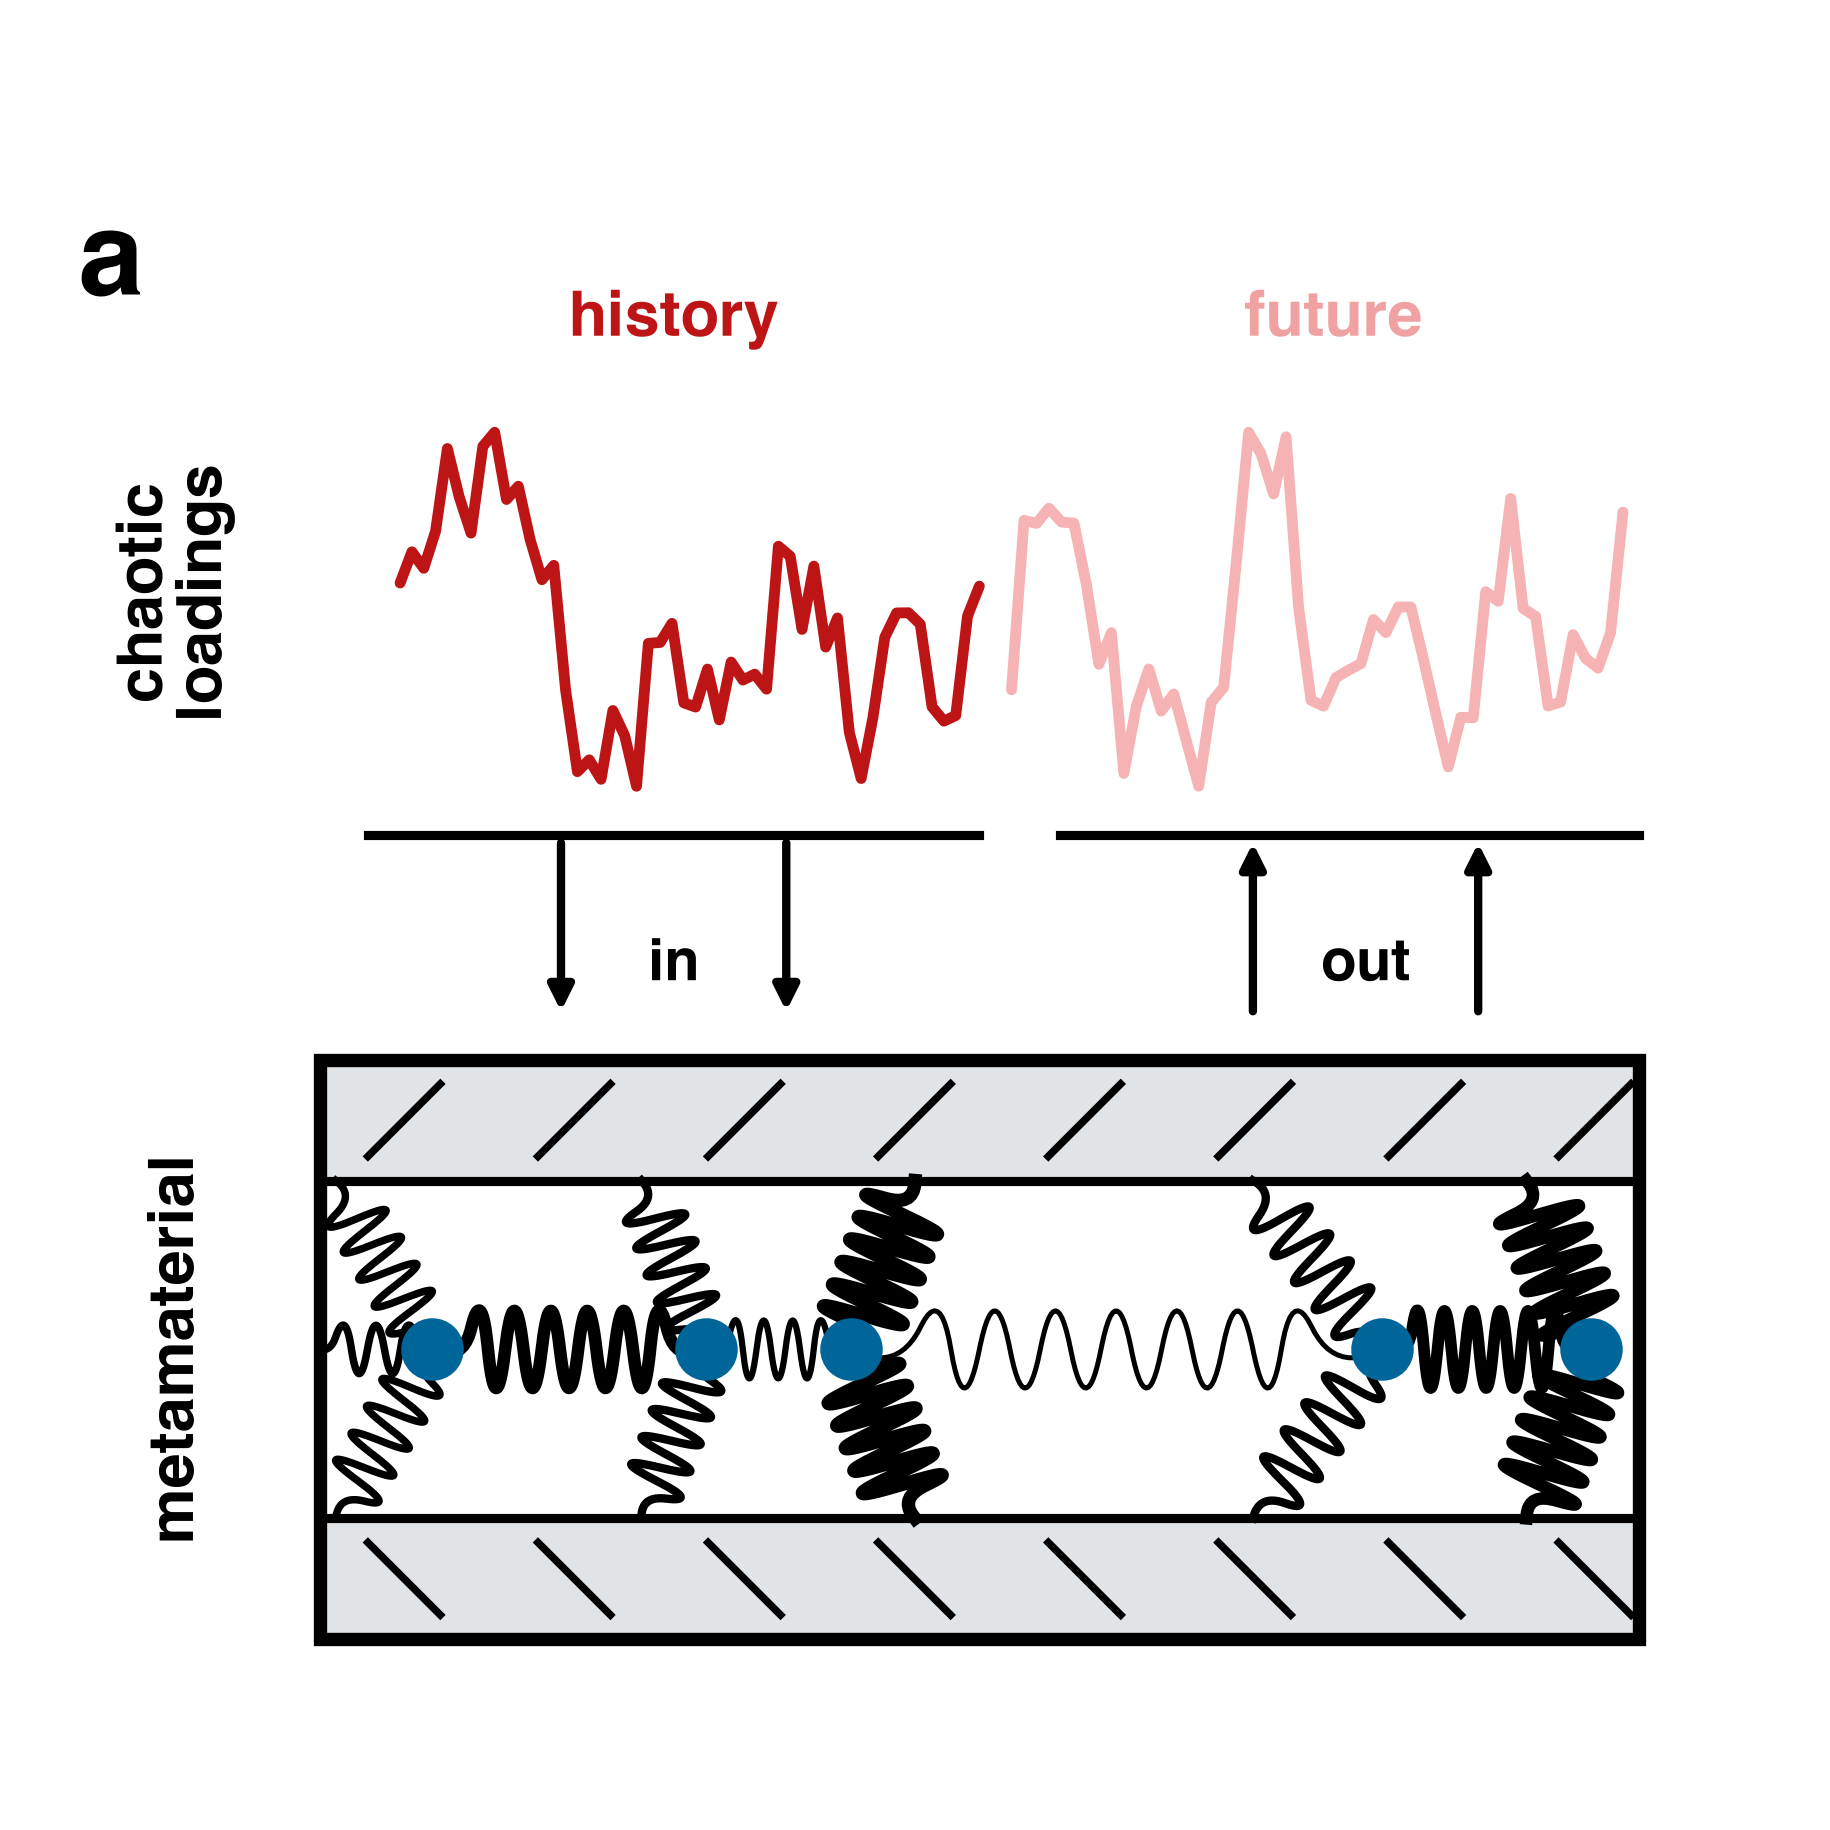

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.interpolate import make_interp_spline


# 1. High-fidelity Spring Generator (Smooth Bezier/Spline look)
def generate_spring(p1, p2, coils=6, width=0.022, lead=0.08):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    vec = p2 - p1
    length = np.linalg.norm(vec)
    u_par = vec / length
    u_perp = np.array([-u_par[1], u_par[0]])

    # Lead-in and lead-out straight wires
    lead_len = lead * length
    active_len = length - 2 * lead_len

    # Zig-zag base coordinates
    t_vals = np.linspace(lead_len, length - lead_len, coils * 2 + 1)
    pts = [p1, p1 + u_par * lead_len]

    for i, t in enumerate(t_vals[1:-1]):
        direction = 1 if (i % 2 == 0) else -1
        pt = p1 + u_par * t + u_perp * (width * direction)
        pts.append(pt)

    pts.append(p1 + u_par * (length - lead_len))
    pts.append(p2)
    pts = np.array(pts)

    # Spline smoothing for authentic spring coils
    distances = np.insert(np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1)), 0, 0)
    spline = make_interp_spline(distances, pts, k=2)
    eval_d = np.linspace(0, distances[-1], 200)
    return spline(eval_d)


# 2. Authentic Chaotic Signal Generator (Brownian / Ornstein-Uhlenbeck)
def generate_chaotic_signal(n_pts=60, seed=12):
    np.random.seed(seed)
    dt = 0.05
    x = np.zeros(n_pts)
    for i in range(1, n_pts):
        # Mean-reverting random walk creates realistic physical oscillations
        x[i] = x[i - 1] * 0.75 + np.random.normal(0, 0.45)
    # Normalize to fixed amplitude
    x = (x - np.min(x)) / (np.max(x) - np.min(x)) * 0.22
    return x


# Plot Setup
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
fig, ax = plt.subplots(figsize=(6.2, 6.2), dpi=300)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_aspect("equal")
ax.axis("off")

# ----------------- SECTION A: TOP SIGNALS -----------------
# Chaotic waves
y_base = 0.58
n_pts = 50
x_hist = np.linspace(0.18, 0.54, n_pts)
y_hist = y_base + generate_chaotic_signal(n_pts, seed=42)

x_fut = np.linspace(0.56, 0.94, n_pts)
y_fut = y_base + generate_chaotic_signal(n_pts, seed=101)

# Wave traces
ax.plot(x_hist, y_hist, color="#bd1515", lw=2.6, solid_capstyle="round")
ax.plot(x_fut, y_fut, color="#f5b3b3", lw=2.6, solid_capstyle="round")

# Baselines under signals
ax.plot([0.16, 0.54], [0.55, 0.55], color="black", lw=2.2)
ax.plot([0.59, 0.95], [0.55, 0.55], color="black", lw=2.2)

# Titles
ax.text(0.35, 0.86, "history", color="#bd1515", fontsize=15, weight="bold", ha="center")
ax.text(0.76, 0.86, "future", color="#f0a1a1", fontsize=15, weight="bold", ha="center")

# Arrows (in / out)
arrow_prop = dict(arrowstyle="-|>", lw=2, mutation_scale=12, color="black")
ax.annotate("", xy=(0.28, 0.435), xytext=(0.28, 0.55), arrowprops=arrow_prop)
ax.annotate("", xy=(0.42, 0.435), xytext=(0.42, 0.55), arrowprops=arrow_prop)
ax.text(0.35, 0.47, "in", fontsize=14, weight="bold", ha="center", va="center")

ax.annotate("", xy=(0.71, 0.55), xytext=(0.71, 0.435), arrowprops=arrow_prop)
ax.annotate("", xy=(0.85, 0.55), xytext=(0.85, 0.435), arrowprops=arrow_prop)
ax.text(0.78, 0.47, "out", fontsize=14, weight="bold", ha="center", va="center")

# ----------------- SECTION B: METAMATERIAL -----------------
box_x0, box_x1 = 0.13, 0.95
y_bot, y_top = 0.05, 0.41
plate_th = 0.075

# Outer housing box
outer_box = patches.Rectangle(
    (box_x0, y_bot),
    box_x1 - box_x0,
    y_top - y_bot,
    edgecolor="black",
    facecolor="none",
    lw=3.2,
    zorder=10,
)
ax.add_patch(outer_box)

# Top & Bottom mounting plates
plate_top = patches.Rectangle(
    (box_x0, y_top - plate_th),
    box_x1 - box_x0,
    plate_th,
    edgecolor="black",
    facecolor="#e1e4e6",
    lw=2.2,
    zorder=2,
)
plate_bot = patches.Rectangle(
    (box_x0, y_bot),
    box_x1 - box_x0,
    plate_th,
    edgecolor="black",
    facecolor="#e1e4e6",
    lw=2.2,
    zorder=2,
)
ax.add_patch(plate_top)
ax.add_patch(plate_bot)

# Ground hatching (slashes)
for x in np.linspace(box_x0 + 0.03, box_x1 - 0.05, 8):
    ax.plot(
        [x, x + 0.045],
        [y_top - plate_th + 0.015, y_top - 0.015],
        color="black",
        lw=1.8,
        zorder=3,
    )
    ax.plot(
        [x, x + 0.045],
        [y_bot + plate_th - 0.015, y_bot + 0.015],
        color="black",
        lw=1.8,
        zorder=3,
    )

# Center Nodes
nodes_x = [0.20, 0.37, 0.46, 0.79, 0.92]
node_y = 0.23

# Horizontal connecting springs (with varied stiffness/thickness)
spring_configs = [
    {"coils": 6, "width": 0.024, "lw": 3.0},  # stiff thick spring
    {"coils": 4, "width": 0.018, "lw": 1.5},  # small spring
    {"coils": 7, "width": 0.024, "lw": 1.2},  # soft/thin spring
    {"coils": 6, "width": 0.024, "lw": 2.8},  # thick spring
]

# Side boundaries to outer nodes
s_left = generate_spring(
    (box_x0, node_y), (nodes_x[0], node_y), coils=3, width=0.015, lead=0.05
)
ax.plot(s_left[:, 0], s_left[:, 1], color="black", lw=1.8)

for i in range(len(nodes_x) - 1):
    cfg = spring_configs[i]
    curve = generate_spring(
        (nodes_x[i], node_y),
        (nodes_x[i + 1], node_y),
        coils=cfg["coils"],
        width=cfg["width"],
        lead=0.1,
    )
    ax.plot(curve[:, 0], curve[:, 1], color="black", lw=cfg["lw"], zorder=4)

# Diagonal anchors connecting nodes to top/bottom plates
diagonal_pairs = [
    # (node_index, (target_x, target_y), coils, width, lw)
    (0, (box_x0 + 0.01, y_top - plate_th), 5, 0.018, 1.8),
    (0, (box_x0 + 0.01, y_bot + plate_th), 5, 0.018, 1.8),
    (1, (0.33, y_top - plate_th), 5, 0.018, 2.0),
    (1, (0.33, y_bot + plate_th), 5, 0.018, 2.0),
    (2, (0.50, y_top - plate_th), 6, 0.025, 3.2),
    (2, (0.50, y_bot + plate_th), 6, 0.025, 3.2),
    (3, (0.71, y_top - plate_th), 5, 0.018, 2.0),
    (3, (0.71, y_bot + plate_th), 5, 0.018, 2.0),
    (4, (0.88, y_top - plate_th), 6, 0.025, 3.0),
    (4, (0.88, y_bot + plate_th), 6, 0.025, 3.0),
]

for n_idx, target, coils, width, lw in diagonal_pairs:
    curve = generate_spring(
        (nodes_x[n_idx], node_y), target, coils=coils, width=width, lead=0.1
    )
    ax.plot(curve[:, 0], curve[:, 1], color="black", lw=lw, zorder=4)

# Draw Node circles over springs
for x in nodes_x:
    ax.plot(x, node_y, "o", color="#006699", markersize=14, zorder=6)

# ----------------- SECTION C: LABELS -----------------
ax.text(-0.02, 0.94, "a", fontsize=28, weight="bold", va="top")
ax.text(
    0.04,
    0.70,
    "chaotic\nloadings",
    fontsize=15,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)
ax.text(
    0.04,
    0.23,
    "metamaterial",
    fontsize=15,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)

plt.tight_layout()
# plt.savefig("metamaterial_publication.svg", bbox_inches="tight")
# plt.savefig("metamaterial_publication.png", bbox_inches="tight", dpi=300)
plt.show()

/var/folders/0r/235txxxd1p73wr0r5k9v6mqr0000gn/T/ipykernel_86658/3054578604.py:39: RuntimeWarning: invalid value encountered in sqrt
  envelope = np.sin(np.pi * s / spring_len) ** 0.5


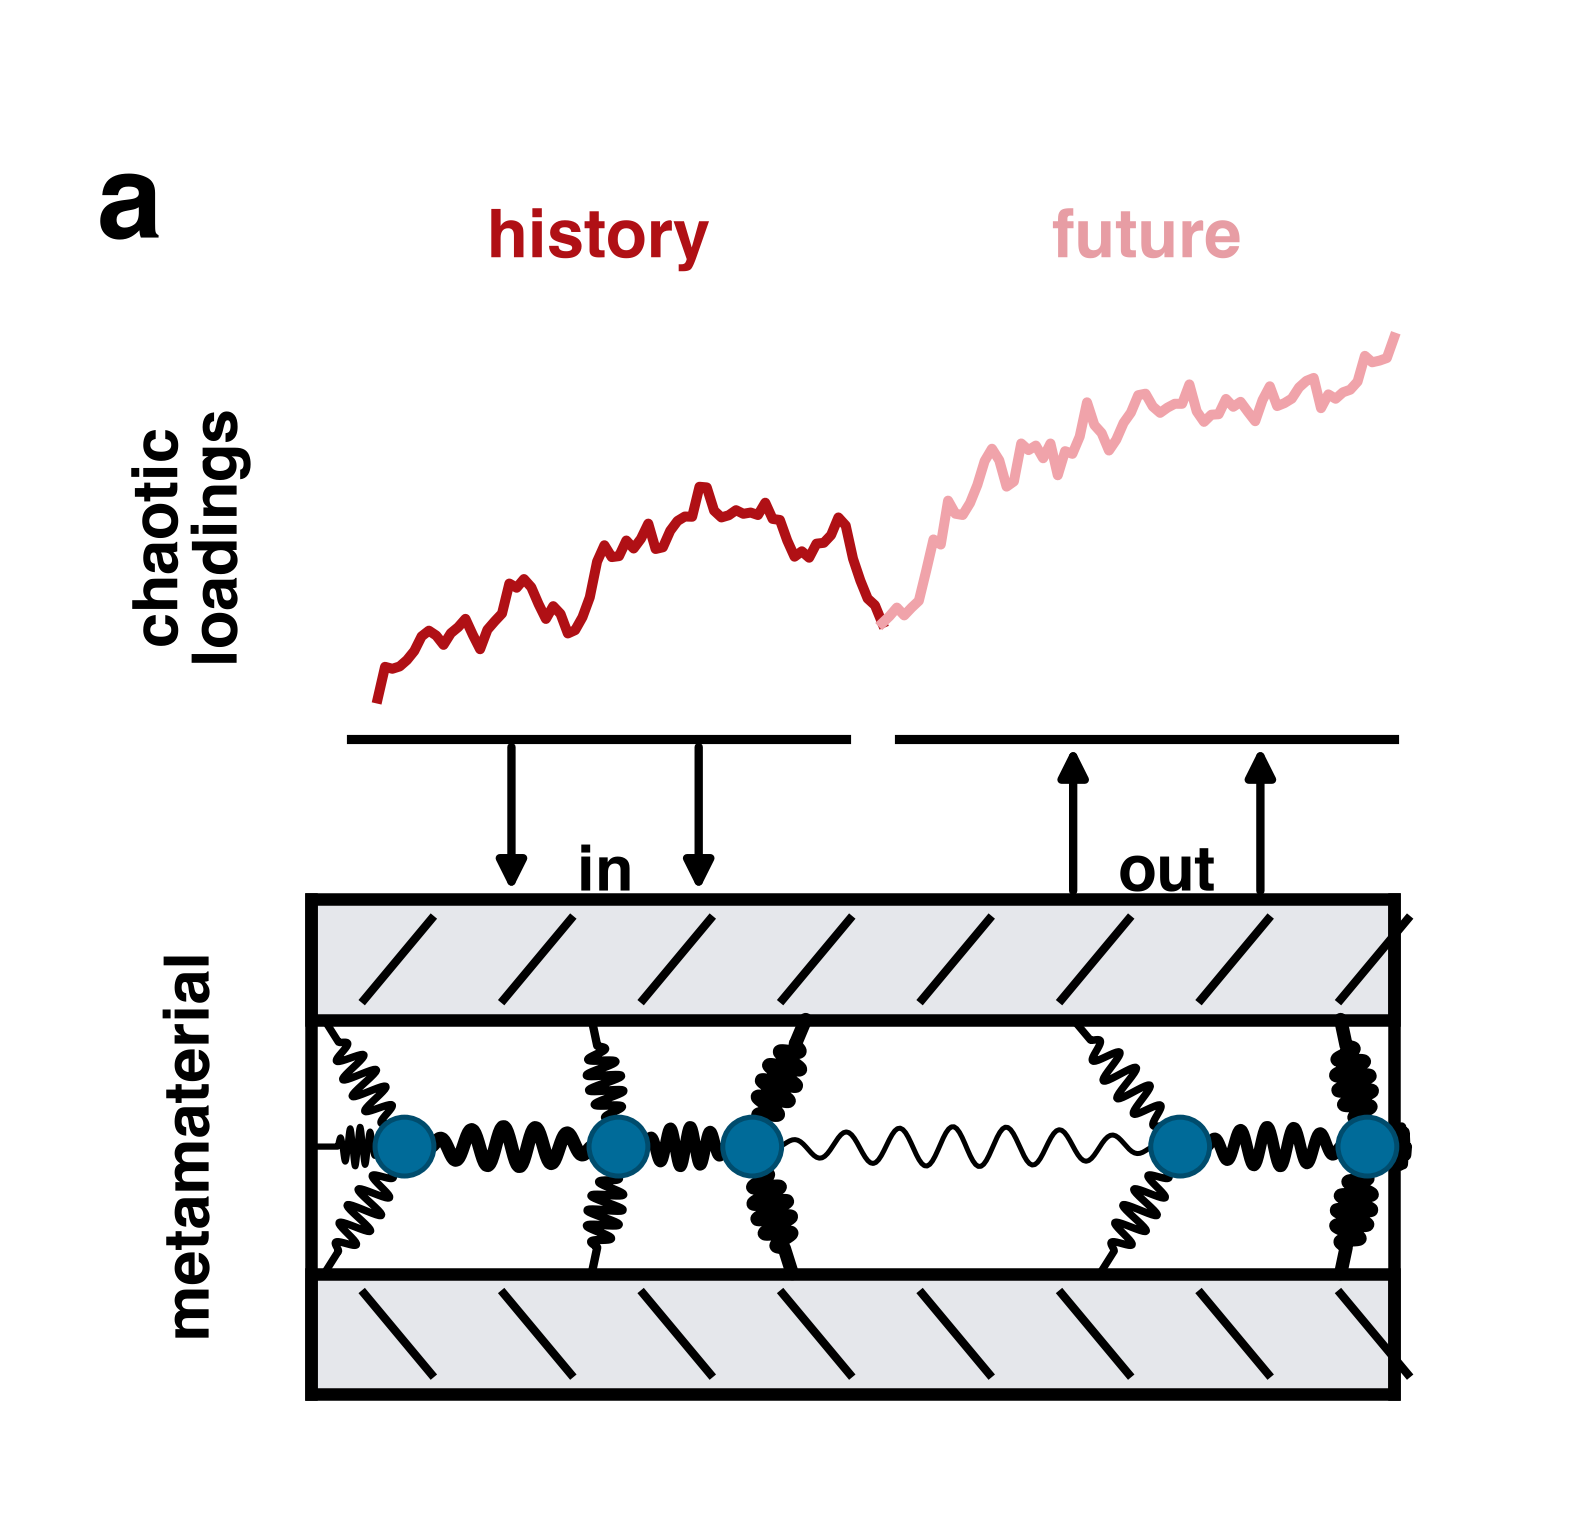

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Set clean sans-serif typography
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=300)
ax.set_xlim(-0.08, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_aspect("equal")
ax.axis("off")


# -------------------------------------------------------------
# 1. Advanced Spring Drawing Function (Coil / Helical appearance)
# -------------------------------------------------------------
def draw_spring(ax, p1, p2, num_coils=6, width=0.016, lw=2.2, color="black", zorder=3):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    dist = np.linalg.norm(p2 - p1)
    if dist == 0:
        return

    dir_vec = (p2 - p1) / dist
    norm_vec = np.array([-dir_vec[1], dir_vec[0]])

    # Straight lead-in segments at each end
    lead = 0.02
    spring_len = max(0.01, dist - 2 * lead)

    # Smooth helical approximation
    n_pts = num_coils * 20
    s = np.linspace(0, spring_len, n_pts)
    phase = 2 * np.pi * num_coils * (s / spring_len)

    # Envelope tapering at ends
    envelope = np.sin(np.pi * s / spring_len) ** 0.5
    offset = width * np.sin(phase) * envelope

    # Build complete path coordinates
    x = [p1[0], (p1 + dir_vec * lead)[0]]
    y = [p1[1], (p1 + dir_vec * lead)[1]]

    for si, off in zip(s, offset):
        pt = p1 + dir_vec * (lead + si) + norm_vec * off
        x.append(pt[0])
        y.append(pt[1])

    x.extend([(p2 - dir_vec * lead)[0], p2[0]])
    y.extend([(p2 - dir_vec * lead)[1], p2[1]])

    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# -------------------------------------------------------------
# 2. Chaotic Loading Signals (Top)
# -------------------------------------------------------------
np.random.seed(18)
n_pts = 70
# Smooth random walk to look like physical chaotic time series
raw_walk = np.cumsum(np.random.randn(n_pts * 2))
raw_walk = (raw_walk - np.min(raw_walk)) / (np.max(raw_walk) - np.min(raw_walk))
signal_y = 0.55 + raw_walk * 0.27

x_all = np.linspace(0.18, 0.94, n_pts * 2)
split_idx = n_pts

# History segment
ax.plot(x_all[:split_idx], signal_y[:split_idx], color="#b01015", lw=2.4)
ax.plot([0.16, 0.53], [0.52, 0.52], color="black", lw=2.2)
ax.text(
    0.345, 0.88, "history", color="#b01015", fontsize=16, weight="bold", ha="center"
)

# Future segment (lighter/tinted)
ax.plot(x_all[split_idx - 1 :], signal_y[split_idx - 1 :], color="#f0a3aa", lw=2.4)
ax.plot([0.57, 0.94], [0.52, 0.52], color="black", lw=2.2)
ax.text(0.755, 0.88, "future", color="#e79da4", fontsize=16, weight="bold", ha="center")

# -------------------------------------------------------------
# 3. Transfer Arrows ("in" / "out")
# -------------------------------------------------------------
arrow_down = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color="black")
ax.annotate("", xy=(0.28, 0.40), xytext=(0.28, 0.52), arrowprops=arrow_down)
ax.annotate("", xy=(0.42, 0.40), xytext=(0.42, 0.52), arrowprops=arrow_down)
ax.text(0.35, 0.42, "in", fontsize=15, weight="bold", ha="center", va="center")

arrow_up = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color="black")
ax.annotate("", xy=(0.70, 0.52), xytext=(0.70, 0.40), arrowprops=arrow_up)
ax.annotate("", xy=(0.84, 0.52), xytext=(0.84, 0.40), arrowprops=arrow_up)
ax.text(0.77, 0.42, "out", fontsize=15, weight="bold", ha="center", va="center")

# -------------------------------------------------------------
# 4. Metamaterial Housing & Rigid Boundary Plates
# -------------------------------------------------------------
box_x0, box_x1 = 0.13, 0.94
y_bot_low, y_bot_high = 0.03, 0.12
y_top_low, y_top_high = 0.31, 0.40

# Gray backings with borders
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_top_low),
        box_x1 - box_x0,
        y_top_high - y_top_low,
        facecolor="#e5e7eb",
        edgecolor="black",
        lw=3,
        zorder=2,
    )
)
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_bot_low),
        box_x1 - box_x0,
        y_bot_high - y_bot_low,
        facecolor="#e5e7eb",
        edgecolor="black",
        lw=3,
        zorder=2,
    )
)

# Outer vertical frame lines
ax.plot([box_x0, box_x0], [y_bot_low, y_top_high], color="black", lw=3, zorder=2)
ax.plot([box_x1, box_x1], [y_bot_low, y_top_high], color="black", lw=3, zorder=2)

# Mechanical hatching / ground slashes
for x_hatch in np.linspace(box_x0 + 0.04, box_x1 - 0.04, 8):
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_top_low + 0.015, y_top_high - 0.015],
        color="black",
        lw=2,
        zorder=3,
    )
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_bot_high - 0.015, y_bot_low + 0.015],
        color="black",
        lw=2,
        zorder=3,
    )

# -------------------------------------------------------------
# 5. Nodes and Spring Network
# -------------------------------------------------------------
nodes_x = [0.13, 0.20, 0.36, 0.46, 0.78, 0.92, 0.94]
y_mid = 0.215

# Diagonal boundary springs (Top & Bottom anchorings)
anchors = [
    # (Node X, Top anchor X, Bottom anchor X, coil thickness)
    (0.20, 0.14, 0.14, 1.8),
    (0.36, 0.34, 0.34, 2.0),
    (0.46, 0.50, 0.49, 3.2),
    (0.78, 0.70, 0.72, 1.8),
    (0.92, 0.90, 0.90, 3.2),
]

for nx, tx, bx, w in anchors:
    draw_spring(ax, (nx, y_mid), (tx, y_top_low), num_coils=5, width=0.013, lw=w)
    draw_spring(ax, (nx, y_mid), (bx, y_bot_high), num_coils=5, width=0.013, lw=w)

# Horizontal springs between nodes
h_springs = [
    (nodes_x[0], nodes_x[1], 1.5, 4),
    (nodes_x[1], nodes_x[2], 3.2, 5),
    (nodes_x[2], nodes_x[3], 2.8, 4),
    (nodes_x[3], nodes_x[4], 1.2, 7),  # Soft spring in the gap
    (nodes_x[4], nodes_x[5], 2.8, 5),
    (nodes_x[5], nodes_x[6], 2.2, 4),
]

for x1, x2, lw, coils in h_springs:
    draw_spring(ax, (x1, y_mid), (x2, y_mid), num_coils=coils, width=0.015, lw=lw)

# Draw Central Teal Nodes
for x in nodes_x[1:-1]:
    circle = plt.Circle(
        (x, y_mid), 0.022, facecolor="#006b99", edgecolor="#004c6d", lw=1.2, zorder=6
    )
    ax.add_patch(circle)

# -------------------------------------------------------------
# 6. Panel Labels & Rotated Text
# -------------------------------------------------------------
ax.text(-0.03, 0.92, "a", fontsize=28, weight="bold", va="center", ha="left")

ax.text(
    0.04,
    0.67,
    "chaotic\nloadings",
    fontsize=15,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
    multialignment="center",
)

ax.text(
    0.04,
    0.215,
    "metamaterial",
    fontsize=15,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)

# Export vector for Keynote
plt.savefig(
    "metamaterial_publication_quality.svg", bbox_inches="tight", transparent=True
)
plt.savefig("metamaterial_publication_quality.png", bbox_inches="tight", dpi=300)
plt.show()

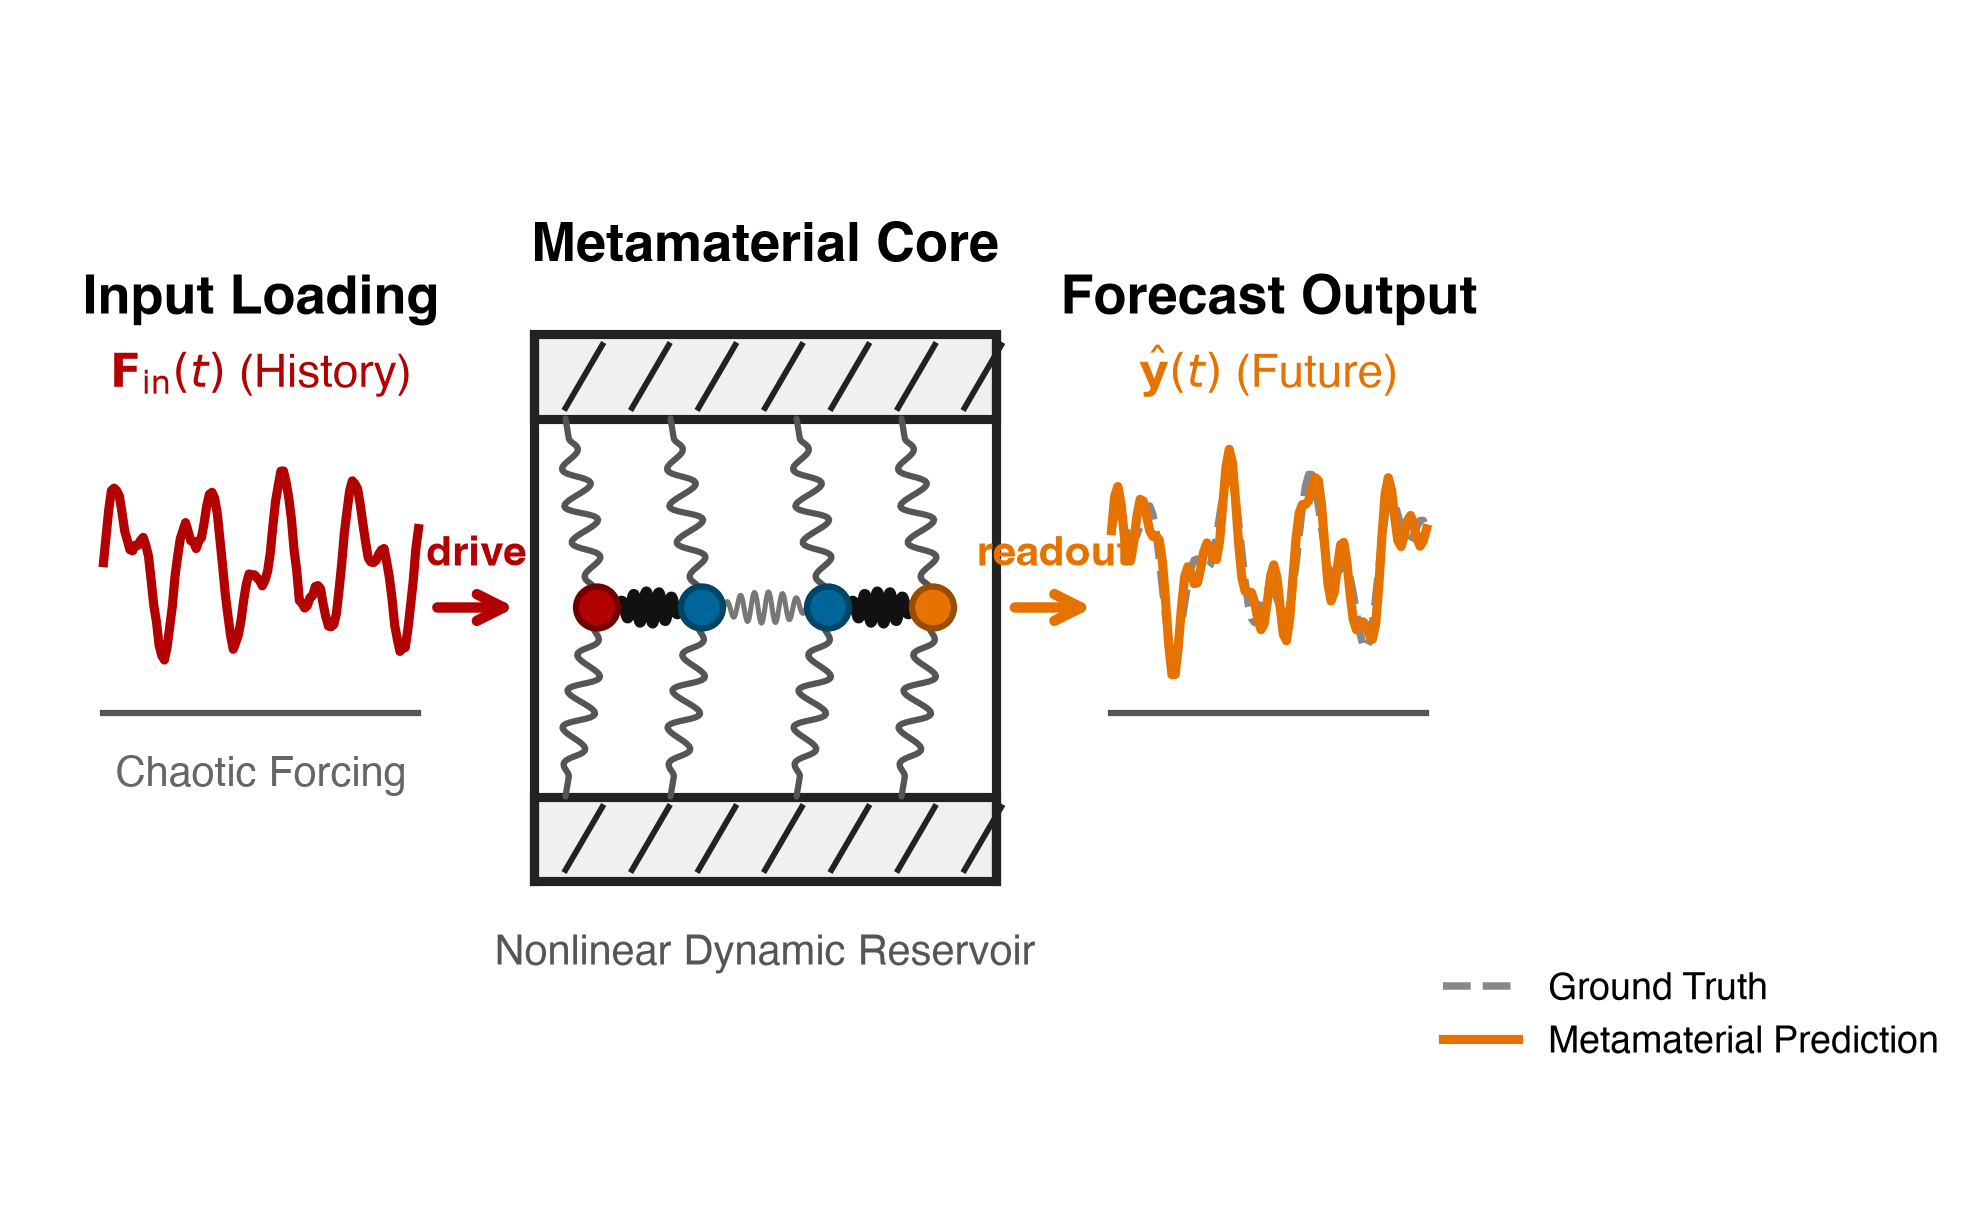

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Set clean presentation typography
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)
ax.set_xlim(-0.05, 1.35)
ax.set_ylim(-0.15, 0.95)
ax.set_aspect("equal")
ax.axis("off")


# -------------------------------------------------------------
# 1. Coil Spring Generator
# -------------------------------------------------------------
def draw_spring(
    ax, p1, p2, num_coils=5, width=0.015, lw=1.8, color="#2b2b2b", zorder=3
):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    dist = np.linalg.norm(p2 - p1)
    if dist == 0:
        return
    dir_vec = (p2 - p1) / dist
    norm_vec = np.array([-dir_vec[1], dir_vec[0]])

    lead = 0.02
    spring_len = max(0.01, dist - 2 * lead)
    s = np.linspace(0, spring_len, num_coils * 18)
    phase = 2 * np.pi * num_coils * (s / spring_len)
    envelope = np.sin(np.pi * s / spring_len) ** 0.5
    offset = width * np.sin(phase) * envelope

    x = [p1[0], (p1 + dir_vec * lead)[0]]
    y = [p1[1], (p1 + dir_vec * lead)[1]]
    for si, off in zip(s, offset):
        pt = p1 + dir_vec * (lead + si) + norm_vec * off
        x.append(pt[0])
        y.append(pt[1])
    x.extend([(p2 - dir_vec * lead)[0], p2[0]])
    y.extend([(p2 - dir_vec * lead)[1], p2[1]])
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# -------------------------------------------------------------
# 2. Simulated Chaotic Time Series (Mackey-Glass / Lorenz-like)
# -------------------------------------------------------------
np.random.seed(42)
t_hist = np.linspace(0, 8 * np.pi, 120)
y_hist = (
    np.sin(t_hist)
    + 0.6 * np.sin(2.3 * t_hist)
    + 0.3 * np.random.randn(len(t_hist)) * 0.15
)
# Rescale to plot coordinates
y_hist_scaled = 0.35 + 0.18 * (y_hist - np.min(y_hist)) / (
    np.max(y_hist) - np.min(y_hist)
)
x_hist_scaled = np.linspace(0.02, 0.32, len(t_hist))

# Output future continuation
t_fut = np.linspace(8 * np.pi, 15 * np.pi, 100)
y_truth = np.sin(t_fut) + 0.6 * np.sin(2.3 * t_fut)
y_truth_scaled = 0.35 + 0.18 * (y_truth - np.min(y_hist)) / (
    np.max(y_hist) - np.min(y_hist)
)
y_pred_scaled = y_truth_scaled + 0.025 * np.sin(
    4 * t_fut
)  # Subtle prediction deviation

x_fut_scaled = np.linspace(0.98, 1.28, len(t_fut))

# -------------------------------------------------------------
# 3. Left Panel: Input Excitation (History)
# -------------------------------------------------------------
ax.plot(x_hist_scaled, y_hist_scaled, color="#b30000", lw=2.2, zorder=4)
ax.plot([0.02, 0.32], [0.30, 0.30], color="#555", lw=1.5)

ax.text(0.17, 0.68, "Input Loading", fontsize=13, weight="bold", ha="center")
ax.text(
    0.17,
    0.61,
    r"$\mathbf{F}_{\mathrm{in}}(t)$ (History)",
    color="#b30000",
    fontsize=11,
    ha="center",
)
ax.text(0.17, 0.23, "Chaotic Forcing", color="#666", fontsize=10, ha="center")

# Pipeline Arrow 1 (Input -> Core)
ax.annotate(
    "",
    xy=(0.42, 0.40),
    xytext=(0.33, 0.40),
    arrowprops=dict(arrowstyle="->", lw=2.5, color="#b30000", mutation_scale=16),
)
ax.text(0.375, 0.44, "drive", color="#b30000", fontsize=10, weight="bold", ha="center")

# -------------------------------------------------------------
# 4. Center Panel: Metamaterial Reservoir Lattice
# -------------------------------------------------------------
core_x0, core_x1 = 0.43, 0.87
y_bot_low, y_bot_high = 0.14, 0.22
y_top_low, y_top_high = 0.58, 0.66
y_mid = 0.40

# Rigid boundary plates with cross-hatch
for y_low, y_high in [(y_top_low, y_top_high), (y_bot_low, y_bot_high)]:
    ax.add_patch(
        patches.Rectangle(
            (core_x0, y_low),
            core_x1 - core_x0,
            y_high - y_low,
            facecolor="#eef0f2",
            edgecolor="#222",
            lw=2.2,
            zorder=2,
        )
    )
    for hx in np.linspace(core_x0 + 0.03, core_x1 - 0.03, 7):
        ax.plot(
            [hx, hx + 0.035],
            [y_low + 0.01, y_high - 0.01],
            color="#222",
            lw=1.4,
            zorder=2,
        )

# Outer frame lines
ax.plot([core_x0, core_x0], [y_bot_low, y_top_high], color="#222", lw=2.2)
ax.plot([core_x1, core_x1], [y_bot_low, y_top_high], color="#222", lw=2.2)

# Node Layout (Input node, Internal reservoir, Output readout node)
nodes = [
    {"x": 0.49, "type": "in"},  # Driven input node
    {"x": 0.59, "type": "hidden"},  # Internal reservoir nodes
    {"x": 0.71, "type": "hidden"},
    {"x": 0.81, "type": "out"},  # Readout node
]

# Diagonal truss springs
for n in nodes:
    draw_spring(
        ax,
        (n["x"], y_mid),
        (n["x"] - 0.03, y_top_low),
        num_coils=4,
        lw=1.5,
        color="#555",
    )
    draw_spring(
        ax,
        (n["x"], y_mid),
        (n["x"] - 0.03, y_bot_high),
        num_coils=4,
        lw=1.5,
        color="#555",
    )

# Horizontal coupling springs
draw_spring(
    ax,
    (nodes[0]["x"], y_mid),
    (nodes[1]["x"], y_mid),
    num_coils=5,
    lw=2.6,
    color="#111",
)
draw_spring(
    ax,
    (nodes[1]["x"], y_mid),
    (nodes[2]["x"], y_mid),
    num_coils=6,
    lw=1.2,
    color="#777",
)
draw_spring(
    ax,
    (nodes[2]["x"], y_mid),
    (nodes[3]["x"], y_mid),
    num_coils=5,
    lw=2.6,
    color="#111",
)

# Draw Nodes with functional color-coding
for n in nodes:
    if n["type"] == "in":
        col, edge = "#b30000", "#700000"  # Red = driven node
    elif n["type"] == "out":
        col, edge = "#e67300", "#994d00"  # Orange = sensor node
    else:
        col, edge = "#006699", "#004466"  # Teal = internal hidden states

    ax.add_patch(
        plt.Circle(
            (n["x"], y_mid), 0.020, facecolor=col, edgecolor=edge, lw=1.5, zorder=6
        )
    )

# Center Panel Titles
ax.text(0.65, 0.73, "Metamaterial Core", fontsize=13, weight="bold", ha="center")
ax.text(
    0.65, 0.06, "Nonlinear Dynamic Reservoir", color="#555", fontsize=10, ha="center"
)

# Pipeline Arrow 2 (Core -> Output)
ax.annotate(
    "",
    xy=(0.97, 0.40),
    xytext=(0.88, 0.40),
    arrowprops=dict(arrowstyle="->", lw=2.5, color="#e67300", mutation_scale=16),
)
ax.text(
    0.925, 0.44, "readout", color="#e67300", fontsize=10, weight="bold", ha="center"
)

# -------------------------------------------------------------
# 5. Right Panel: Output & Prediction Overlay
# -------------------------------------------------------------
# Actual continuation (dashed gray)
ax.plot(
    x_fut_scaled,
    y_truth_scaled,
    color="#888",
    lw=1.8,
    linestyle="--",
    label="Ground Truth",
    zorder=3,
)
# Predicted future (solid orange/pink)
ax.plot(
    x_fut_scaled,
    y_pred_scaled,
    color="#e67300",
    lw=2.2,
    label="Metamaterial Prediction",
    zorder=4,
)
ax.plot([0.98, 1.28], [0.30, 0.30], color="#555", lw=1.5)

ax.text(1.13, 0.68, "Forecast Output", fontsize=13, weight="bold", ha="center")
ax.text(
    1.13,
    0.61,
    r"$\hat{\mathbf{y}}(t)$ (Future)",
    color="#e67300",
    fontsize=11,
    ha="center",
)

# Clean legend for prediction fidelity
leg = ax.legend(
    frameon=False, loc="lower center", bbox_to_anchor=(1.13, 0.08), fontsize=9
)

# Save high-res vector for Keynote
# plt.savefig("pipeline_metamaterial.svg", bbox_inches="tight", transparent=True)
# plt.savefig("pipeline_metamaterial.png", bbox_inches="tight", dpi=300)
plt.show()

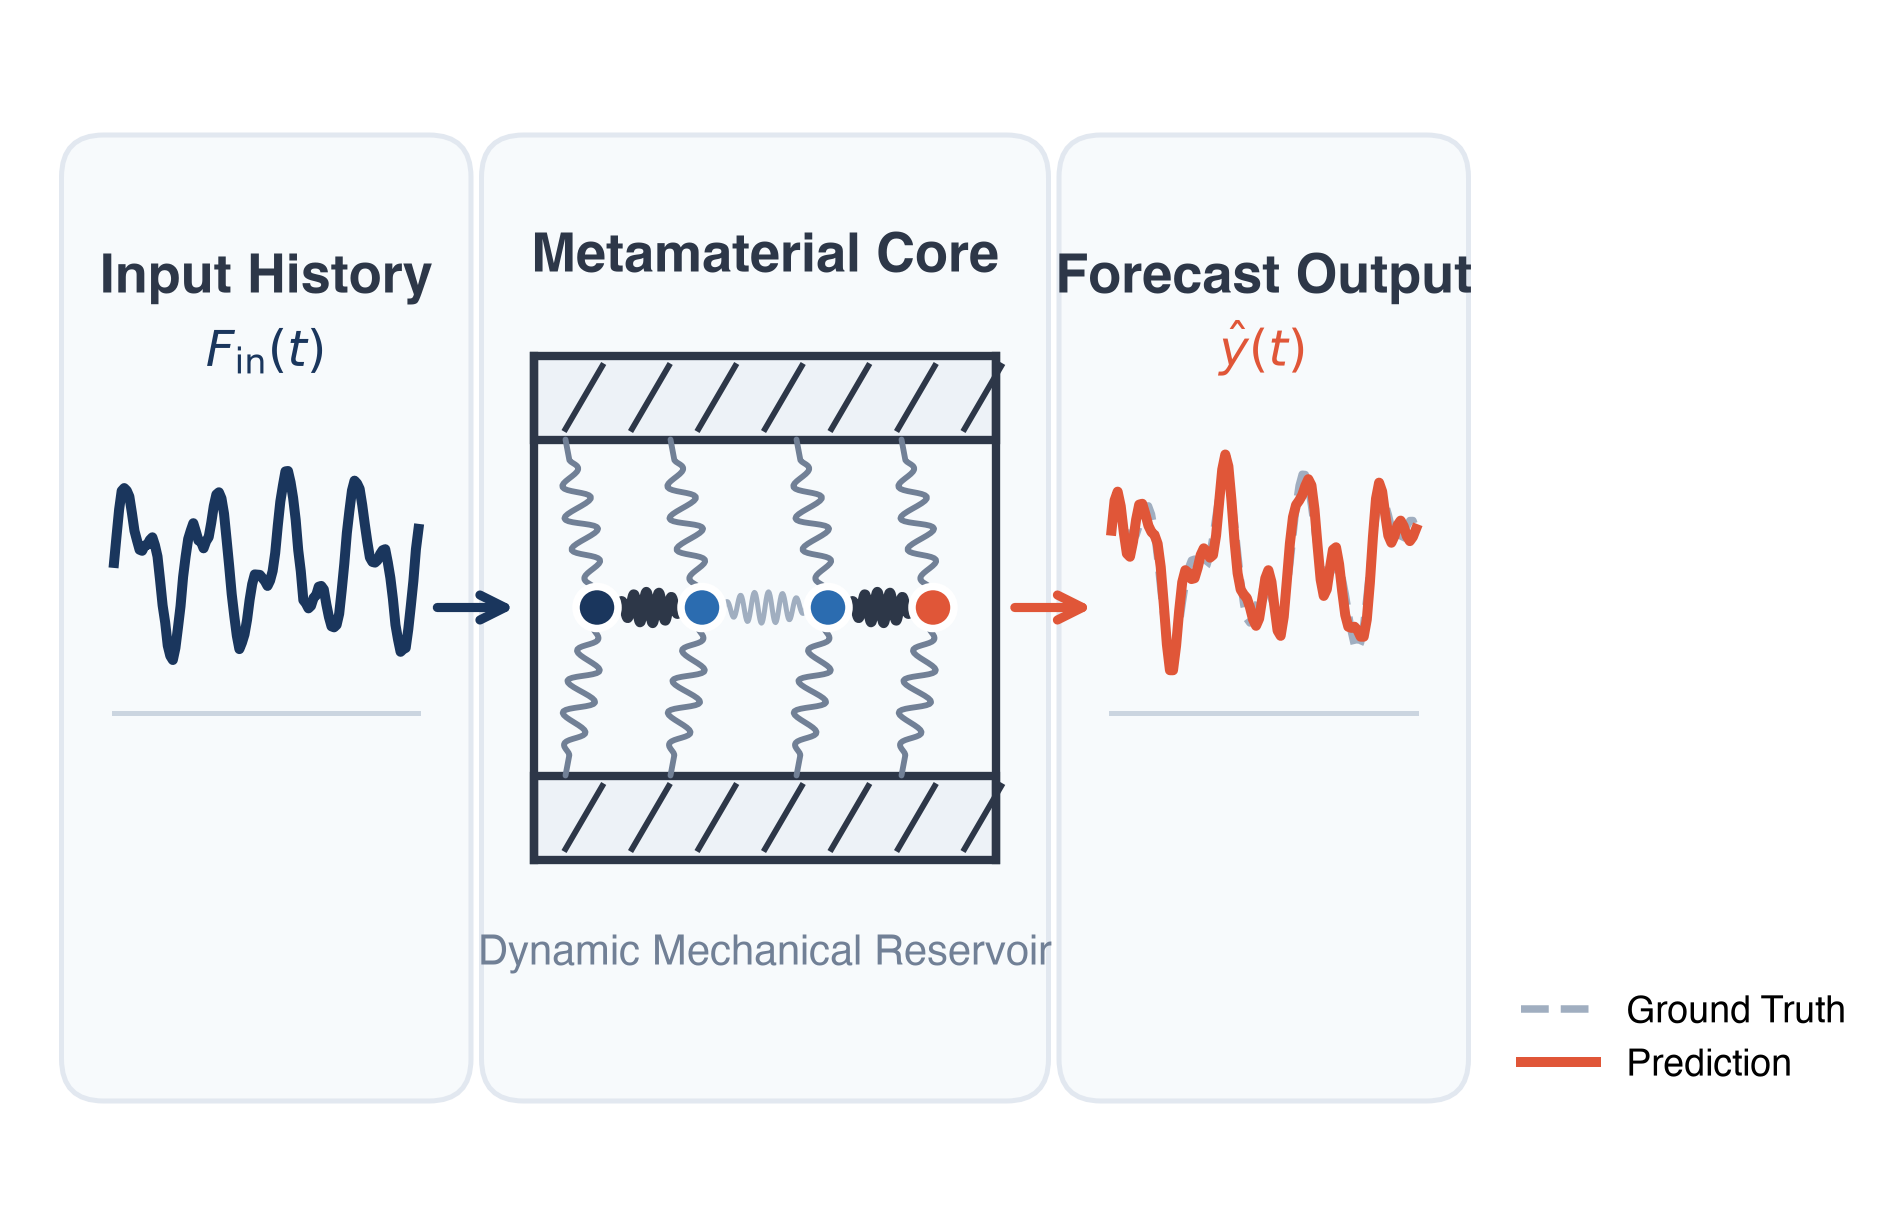

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)
ax.set_xlim(-0.05, 1.35)
ax.set_ylim(-0.15, 0.95)
ax.set_aspect("equal")
ax.axis("off")

# Palette definition (Theme A)
C_HIST = "#1A365D"  # Deep Navy
C_PRED = "#E05638"  # Warm Coral
C_TRUTH = "#A0AEC0"  # Slate Gray
C_NODE = "#2B6CB0"  # Mid Blue
C_FRAME = "#2D3748"  # Dark Charcoal
C_BG = "#F7FAFC"  # Soft container background
C_PLATE = "#EDF2F7"  # Boundary fill


def draw_spring(
    ax, p1, p2, num_coils=5, width=0.015, lw=1.8, color="#4A5568", zorder=3
):
    p1, p2 = np.array(p1, dtype=float), np.array(p2, dtype=float)
    dist = np.linalg.norm(p2 - p1)
    if dist == 0:
        return
    dir_vec = (p2 - p1) / dist
    norm_vec = np.array([-dir_vec[1], dir_vec[0]])

    lead = 0.02
    spring_len = max(0.01, dist - 2 * lead)
    s = np.linspace(0, spring_len, num_coils * 18)
    phase = 2 * np.pi * num_coils * (s / spring_len)
    envelope = np.sin(np.pi * s / spring_len) ** 0.5
    offset = width * np.sin(phase) * envelope

    x = [p1[0], (p1 + dir_vec * lead)[0]]
    y = [p1[1], (p1 + dir_vec * lead)[1]]
    for si, off in zip(s, offset):
        pt = p1 + dir_vec * (lead + si) + norm_vec * off
        x.append(pt[0])
        y.append(pt[1])
    x.extend([(p2 - dir_vec * lead)[0], p2[0]])
    y.extend([(p2 - dir_vec * lead)[1], p2[1]])
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# 1. Subtle Background Cards for Visual Grouping
for x0, w in [(0.00, 0.35), (0.40, 0.50), (0.95, 0.35)]:
    card = patches.FancyBboxPatch(
        (x0, -0.05),
        w,
        0.88,
        boxstyle="round,pad=0.02,rounding_size=0.04",
        facecolor=C_BG,
        edgecolor="#E2E8F0",
        lw=1.2,
        zorder=0,
    )
    ax.add_patch(card)

# 2. Time-series Signals
np.random.seed(42)
t_hist = np.linspace(0, 8 * np.pi, 120)
y_hist = (
    np.sin(t_hist) + 0.6 * np.sin(2.3 * t_hist) + 0.04 * np.random.randn(len(t_hist))
)
y_hist_s = 0.35 + 0.18 * (y_hist - np.min(y_hist)) / (np.max(y_hist) - np.min(y_hist))
x_hist_s = np.linspace(0.03, 0.32, len(t_hist))

t_fut = np.linspace(8 * np.pi, 15 * np.pi, 100)
y_truth = np.sin(t_fut) + 0.6 * np.sin(2.3 * t_fut)
y_truth_s = 0.35 + 0.18 * (y_truth - np.min(y_hist)) / (np.max(y_hist) - np.min(y_hist))
y_pred_s = y_truth_s + 0.02 * np.sin(4 * t_fut)
x_fut_s = np.linspace(0.98, 1.27, len(t_fut))

# Left: Input Curve
ax.plot(x_hist_s, y_hist_s, color=C_HIST, lw=2.4, zorder=4)
ax.plot([0.03, 0.32], [0.30, 0.30], color="#CBD5E0", lw=1.2)
ax.text(
    0.175, 0.70, "Input History", fontsize=13, weight="bold", color=C_FRAME, ha="center"
)
ax.text(0.175, 0.63, r"$F_{\mathrm{in}}(t)$", fontsize=12, color=C_HIST, ha="center")

# Connection 1: Input to Metamaterial
ax.annotate(
    "",
    xy=(0.42, 0.40),
    xytext=(0.33, 0.40),
    arrowprops=dict(arrowstyle="->", lw=2.2, color=C_HIST, mutation_scale=15),
)

# Center: Metamaterial Core
core_x0, core_x1 = 0.43, 0.87
y_bot_low, y_bot_high = 0.16, 0.24
y_top_low, y_top_high = 0.56, 0.64
y_mid = 0.40

for y_low, y_high in [(y_top_low, y_top_high), (y_bot_low, y_bot_high)]:
    ax.add_patch(
        patches.Rectangle(
            (core_x0, y_low),
            core_x1 - core_x0,
            y_high - y_low,
            facecolor=C_PLATE,
            edgecolor=C_FRAME,
            lw=2,
            zorder=2,
        )
    )
    for hx in np.linspace(core_x0 + 0.03, core_x1 - 0.03, 7):
        ax.plot(
            [hx, hx + 0.035],
            [y_low + 0.01, y_high - 0.01],
            color=C_FRAME,
            lw=1.4,
            zorder=2,
        )

ax.plot([core_x0, core_x0], [y_bot_low, y_top_high], color=C_FRAME, lw=2)
ax.plot([core_x1, core_x1], [y_bot_low, y_top_high], color=C_FRAME, lw=2)

nodes = [0.49, 0.59, 0.71, 0.81]
for xn in nodes:
    draw_spring(
        ax, (xn, y_mid), (xn - 0.03, y_top_low), num_coils=4, lw=1.4, color="#718096"
    )
    draw_spring(
        ax, (xn, y_mid), (xn - 0.03, y_bot_high), num_coils=4, lw=1.4, color="#718096"
    )

draw_spring(
    ax, (nodes[0], y_mid), (nodes[1], y_mid), num_coils=5, lw=2.4, color=C_FRAME
)
draw_spring(
    ax, (nodes[1], y_mid), (nodes[2], y_mid), num_coils=6, lw=1.2, color="#A0AEC0"
)
draw_spring(
    ax, (nodes[2], y_mid), (nodes[3], y_mid), num_coils=5, lw=2.4, color=C_FRAME
)

# Nodes: input (Navy), hidden (Mid-Blue), output (Coral)
node_colors = [C_HIST, C_NODE, C_NODE, C_PRED]
for xn, col in zip(nodes, node_colors):
    ax.add_patch(
        plt.Circle(
            (xn, y_mid), 0.020, facecolor=col, edgecolor="white", lw=1.8, zorder=6
        )
    )

ax.text(
    0.65,
    0.72,
    "Metamaterial Core",
    fontsize=13,
    weight="bold",
    color=C_FRAME,
    ha="center",
)
ax.text(
    0.65,
    0.06,
    "Dynamic Mechanical Reservoir",
    fontsize=10,
    color="#718096",
    ha="center",
)

# Connection 2: Metamaterial to Output
ax.annotate(
    "",
    xy=(0.97, 0.40),
    xytext=(0.88, 0.40),
    arrowprops=dict(arrowstyle="->", lw=2.2, color=C_PRED, mutation_scale=15),
)

# Right: Prediction Overlay
ax.plot(
    x_fut_s,
    y_truth_s,
    color=C_TRUTH,
    lw=1.8,
    linestyle="--",
    label="Ground Truth",
    zorder=3,
)
ax.plot(x_fut_s, y_pred_s, color=C_PRED, lw=2.4, label="Prediction", zorder=4)
ax.plot([0.98, 1.27], [0.30, 0.30], color="#CBD5E0", lw=1.2)
ax.text(
    1.125,
    0.70,
    "Forecast Output",
    fontsize=13,
    weight="bold",
    color=C_FRAME,
    ha="center",
)
ax.text(1.125, 0.63, r"$\hat{y}(t)$", fontsize=12, color=C_PRED, ha="center")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(1.125, 0.06), fontsize=9)

# plt.savefig("metamaterial_theme_a.svg", bbox_inches="tight", transparent=True)
# plt.savefig("metamaterial_theme_a.png", bbox_inches="tight", dpi=300)
plt.show()

/var/folders/0r/235txxxd1p73wr0r5k9v6mqr0000gn/T/ipykernel_86658/837270914.py:43: RuntimeWarning: invalid value encountered in sqrt
  envelope = np.sin(np.pi * s / spring_len) ** 0.5


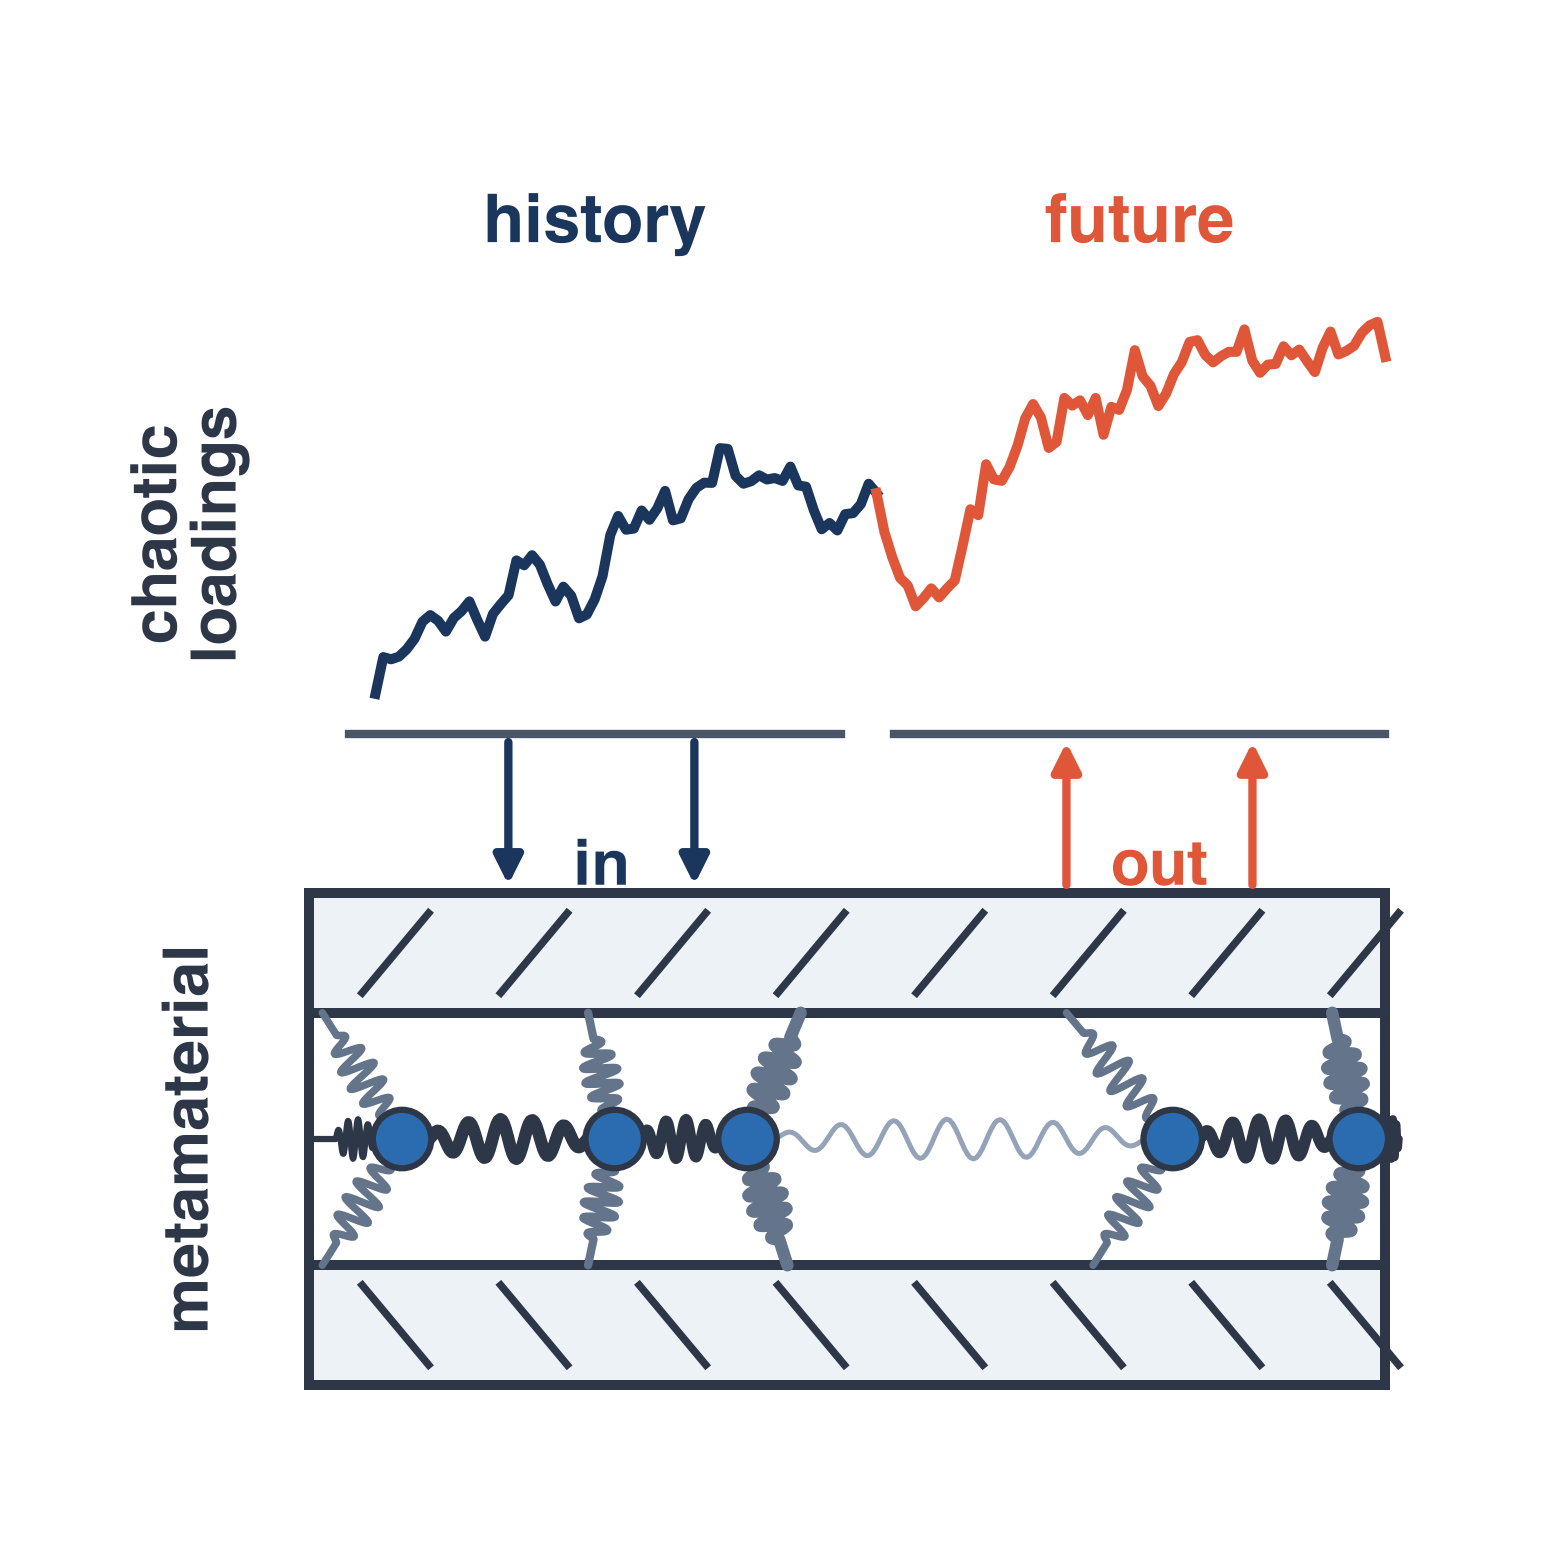

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Clean presentation typography
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=300)
ax.set_xlim(-0.08, 1.05)
ax.set_ylim(-0.08, 1.05)
ax.set_aspect("equal")
ax.axis("off")

# -------------------------------------------------------------
# Color Palette (Theme A: Navy, Coral & Slate)
# -------------------------------------------------------------
C_HIST = "#1A365D"  # Deep Academic Navy (history)
C_FUT = "#E05638"  # Warm Coral (future)
C_NODE = "#2B6CB0"  # Mid-tone Blue
C_FRAME = "#2D3748"  # Dark Charcoal borders
C_PLATE = "#EDF2F7"  # Soft slate boundary fill
C_AXIS = "#4A5568"  # Subdued axis lines
C_SPRING = "#334155"  # Spring steel color


# -------------------------------------------------------------
# 1. Smooth Coiled Spring Function
# -------------------------------------------------------------
def draw_spring(ax, p1, p2, num_coils=5, width=0.015, lw=1.8, color=C_SPRING, zorder=3):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    dist = np.linalg.norm(p2 - p1)
    if dist == 0:
        return
    dir_vec = (p2 - p1) / dist
    norm_vec = np.array([-dir_vec[1], dir_vec[0]])

    lead = 0.02
    spring_len = max(0.01, dist - 2 * lead)
    s = np.linspace(0, spring_len, num_coils * 18)
    phase = 2 * np.pi * num_coils * (s / spring_len)
    envelope = np.sin(np.pi * s / spring_len) ** 0.5
    offset = width * np.sin(phase) * envelope

    x = [p1[0], (p1 + dir_vec * lead)[0]]
    y = [p1[1], (p1 + dir_vec * lead)[1]]
    for si, off in zip(s, offset):
        pt = p1 + dir_vec * (lead + si) + norm_vec * off
        x.append(pt[0])
        y.append(pt[1])
    x.extend([(p2 - dir_vec * lead)[0], p2[0]])
    y.extend([(p2 - dir_vec * lead)[1], p2[1]])
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# -------------------------------------------------------------
# 2. Chaotic Loading Waves (Top Stack)
# -------------------------------------------------------------
np.random.seed(18)
n_pts = 65
raw_walk = np.cumsum(np.random.randn(n_pts * 2))
raw_walk = (raw_walk - np.min(raw_walk)) / (np.max(raw_walk) - np.min(raw_walk))
signal_y = 0.55 + raw_walk * 0.28
x_all = np.linspace(0.18, 0.94, n_pts * 2)
split_idx = n_pts

# History waveform & baseline
ax.plot(x_all[:split_idx], signal_y[:split_idx], color=C_HIST, lw=2.4, zorder=4)
ax.plot([0.16, 0.53], [0.52, 0.52], color=C_AXIS, lw=2.0)
ax.text(0.345, 0.89, "history", color=C_HIST, fontsize=16, weight="bold", ha="center")

# Future waveform & baseline
ax.plot(
    x_all[split_idx - 1 :], signal_y[split_idx - 1 :], color=C_FUT, lw=2.4, zorder=4
)
ax.plot([0.57, 0.94], [0.52, 0.52], color=C_AXIS, lw=2.0)
ax.text(0.755, 0.89, "future", color=C_FUT, fontsize=16, weight="bold", ha="center")

# -------------------------------------------------------------
# 3. Transfer Arrows ("in" / "out")
# -------------------------------------------------------------
arrow_down = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color=C_HIST)
ax.annotate("", xy=(0.28, 0.40), xytext=(0.28, 0.52), arrowprops=arrow_down)
ax.annotate("", xy=(0.42, 0.40), xytext=(0.42, 0.52), arrowprops=arrow_down)
ax.text(
    0.35, 0.42, "in", color=C_HIST, fontsize=15, weight="bold", ha="center", va="center"
)

arrow_up = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color=C_FUT)
ax.annotate("", xy=(0.70, 0.52), xytext=(0.70, 0.40), arrowprops=arrow_up)
ax.annotate("", xy=(0.84, 0.52), xytext=(0.84, 0.40), arrowprops=arrow_up)
ax.text(
    0.77, 0.42, "out", color=C_FUT, fontsize=15, weight="bold", ha="center", va="center"
)

# -------------------------------------------------------------
# 4. Metamaterial Housing & Rigid Boundary Plates (Bottom Stack)
# -------------------------------------------------------------
box_x0, box_x1 = 0.13, 0.94
y_bot_low, y_bot_high = 0.03, 0.12
y_top_low, y_top_high = 0.31, 0.40

# Slate gray boundary plates
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_top_low),
        box_x1 - box_x0,
        y_top_high - y_top_low,
        facecolor=C_PLATE,
        edgecolor=C_FRAME,
        lw=2.4,
        zorder=2,
    )
)
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_bot_low),
        box_x1 - box_x0,
        y_bot_high - y_bot_low,
        facecolor=C_PLATE,
        edgecolor=C_FRAME,
        lw=2.4,
        zorder=2,
    )
)

# Outer vertical frame bounds
ax.plot([box_x0, box_x0], [y_bot_low, y_top_high], color=C_FRAME, lw=2.4, zorder=2)
ax.plot([box_x1, box_x1], [y_bot_low, y_top_high], color=C_FRAME, lw=2.4, zorder=2)

# Boundary slashes
for x_hatch in np.linspace(box_x0 + 0.04, box_x1 - 0.04, 8):
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_top_low + 0.015, y_top_high - 0.015],
        color=C_FRAME,
        lw=1.8,
        zorder=3,
    )
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_bot_high - 0.015, y_bot_low + 0.015],
        color=C_FRAME,
        lw=1.8,
        zorder=3,
    )

# -------------------------------------------------------------
# 5. Nodes and Spring Network
# -------------------------------------------------------------
nodes_x = [0.13, 0.20, 0.36, 0.46, 0.78, 0.92, 0.94]
y_mid = 0.215

# Diagonal boundary springs (Top & Bottom)
anchors = [
    (0.20, 0.14, 0.14, 1.8),
    (0.36, 0.34, 0.34, 2.0),
    (0.46, 0.50, 0.49, 3.0),
    (0.78, 0.70, 0.72, 1.8),
    (0.92, 0.90, 0.90, 3.0),
]

for nx, tx, bx, w in anchors:
    draw_spring(
        ax,
        (nx, y_mid),
        (tx, y_top_low),
        num_coils=5,
        width=0.013,
        lw=w,
        color="#64748B",
    )
    draw_spring(
        ax,
        (nx, y_mid),
        (bx, y_bot_high),
        num_coils=5,
        width=0.013,
        lw=w,
        color="#64748B",
    )

# Horizontal coupling springs
h_springs = [
    (nodes_x[0], nodes_x[1], 1.5, 4, C_FRAME),
    (nodes_x[1], nodes_x[2], 3.0, 5, C_FRAME),
    (nodes_x[2], nodes_x[3], 2.6, 4, C_FRAME),
    (nodes_x[3], nodes_x[4], 1.2, 7, "#94A3B8"),  # Soft coupling in middle
    (nodes_x[4], nodes_x[5], 2.8, 5, C_FRAME),
    (nodes_x[5], nodes_x[6], 2.0, 4, C_FRAME),
]

for x1, x2, lw, coils, col in h_springs:
    draw_spring(
        ax, (x1, y_mid), (x2, y_mid), num_coils=coils, width=0.015, lw=lw, color=col
    )

# Central Blue Nodes
for x in nodes_x[1:-1]:
    circle = plt.Circle(
        (x, y_mid), 0.022, facecolor=C_NODE, edgecolor=C_FRAME, lw=1.5, zorder=6
    )
    ax.add_patch(circle)

# -------------------------------------------------------------
# 6. Panel Letter & Rotated Side Labels
# -------------------------------------------------------------

ax.text(
    0.04,
    0.67,
    "chaotic\nloadings",
    fontsize=15,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
    multialignment="center",
)

ax.text(
    0.04,
    0.215,
    "metamaterial",
    fontsize=15,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
)

# Export clean vector graphic directly for Keynote
# plt.savefig(
#     "metamaterial_clean_original_shape.svg", bbox_inches="tight", transparent=True
# )
# plt.savefig("metamaterial_clean_original_shape.png", bbox_inches="tight", dpi=300)
plt.show()

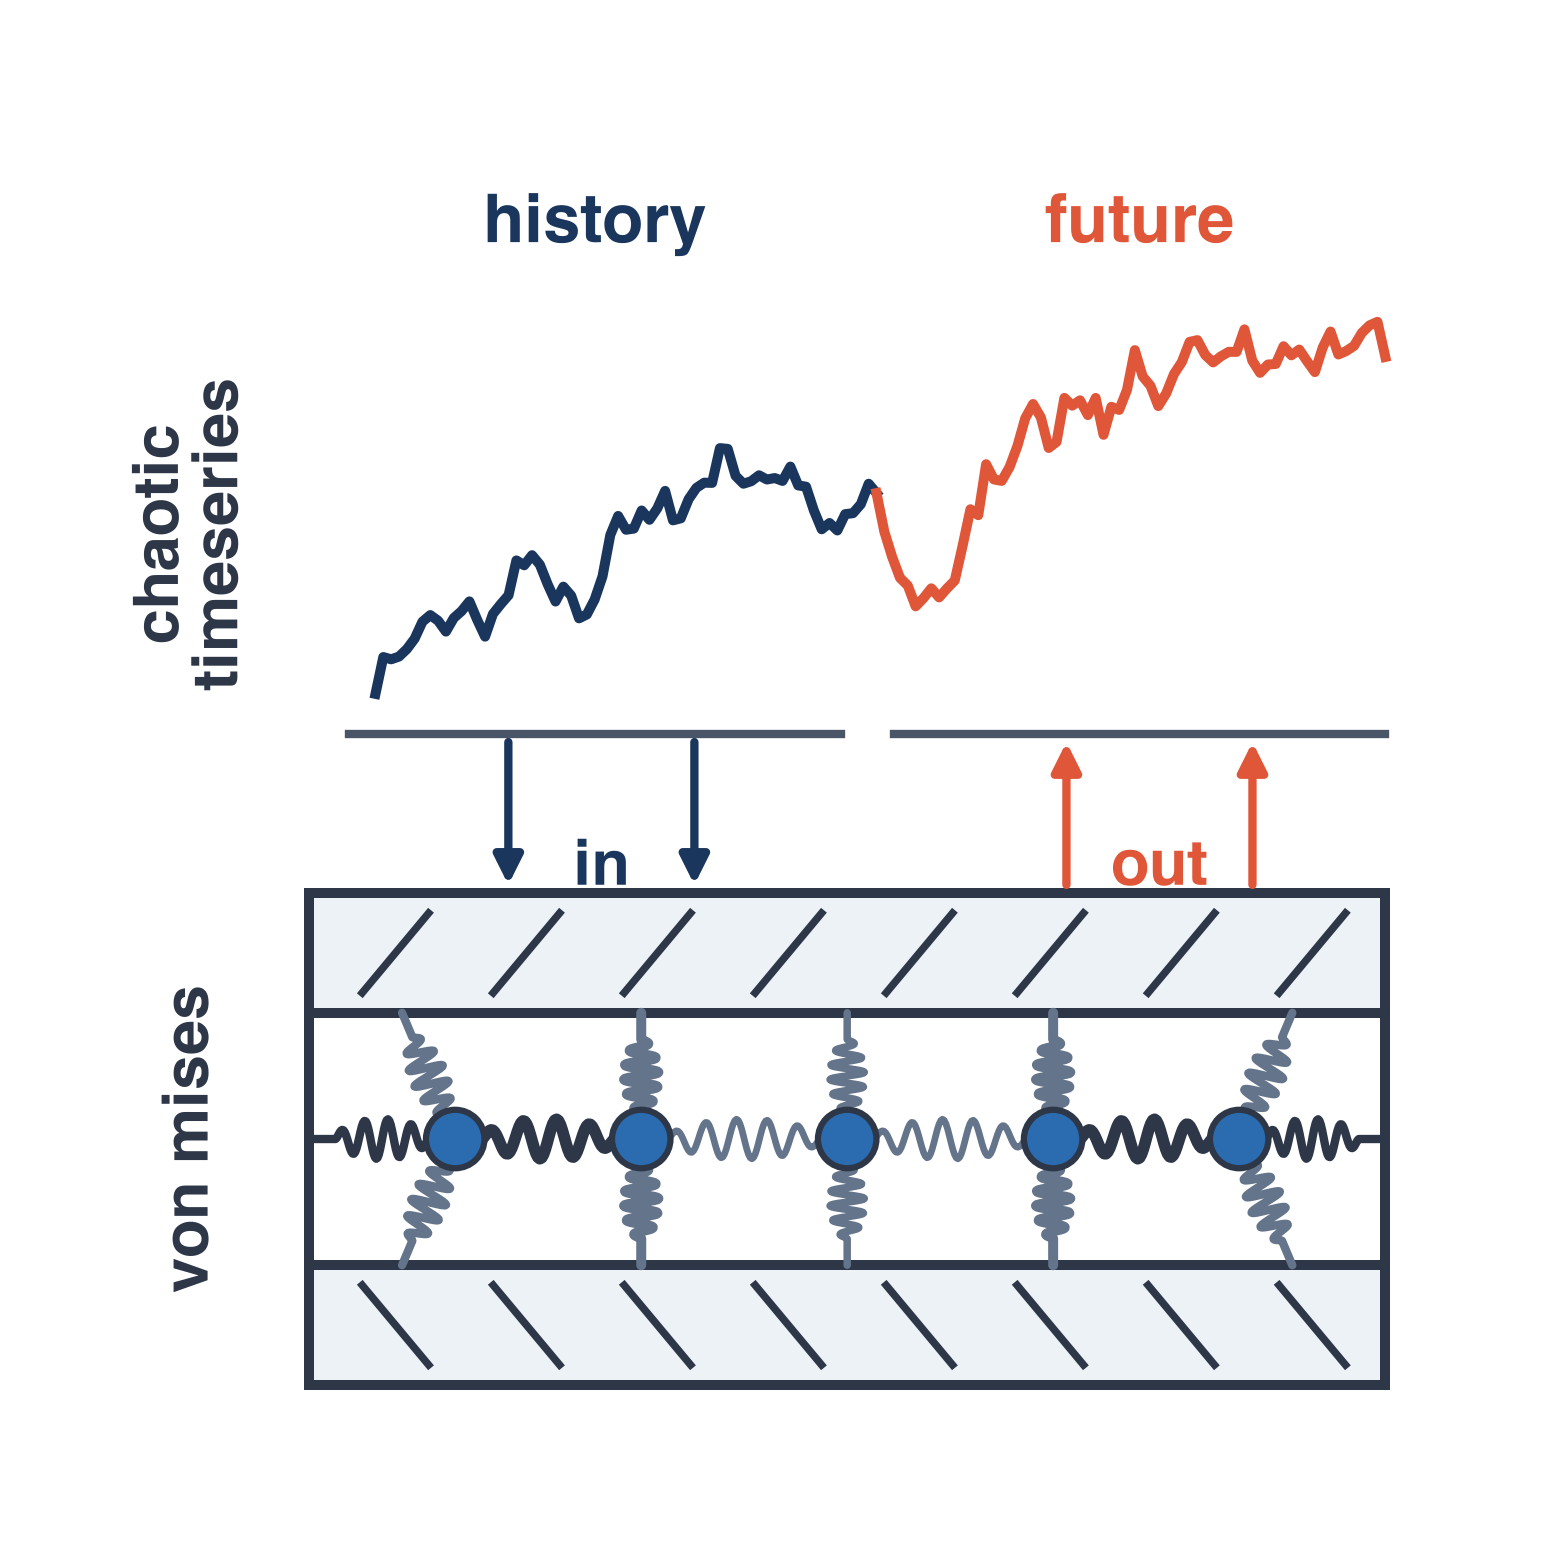

In [15]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np

# Clean presentation typography
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=300)
ax.set_xlim(-0.08, 1.05)
ax.set_ylim(-0.08, 1.05)
ax.set_aspect("equal")
ax.axis("off")

# -------------------------------------------------------------
# Color Palette
# -------------------------------------------------------------
C_HIST = "#1A365D"  # Deep Academic Navy
C_FUT = "#E05638"  # Warm Coral
C_NODE = "#2B6CB0"  # Mid-tone Blue
C_FRAME = "#2D3748"  # Dark Charcoal borders
C_PLATE = "#EDF2F7"  # Soft slate boundary fill
C_AXIS = "#4A5568"  # Subdued axis lines
C_SPRING = "#334155"  # Spring steel color


# -------------------------------------------------------------
# 1. Smooth Coiled Spring Function
# -------------------------------------------------------------
def draw_spring(ax, p1, p2, num_coils=5, width=0.015, lw=1.8, color=C_SPRING, zorder=3):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    dist = np.linalg.norm(p2 - p1)
    if dist == 0:
        return
    dir_vec = (p2 - p1) / dist
    norm_vec = np.array([-dir_vec[1], dir_vec[0]])

    lead = 0.02
    spring_len = max(0.01, dist - 2 * lead)
    s = np.linspace(0, spring_len, num_coils * 18)
    phase = 2 * np.pi * num_coils * (s / spring_len)
    envelope = np.sin(np.pi * s / spring_len) ** 0.5
    offset = width * np.sin(phase) * envelope

    x = [p1[0], (p1 + dir_vec * lead)[0]]
    y = [p1[1], (p1 + dir_vec * lead)[1]]
    for si, off in zip(s, offset):
        pt = p1 + dir_vec * (lead + si) + norm_vec * off
        x.append(pt[0])
        y.append(pt[1])
    x.extend([(p2 - dir_vec * lead)[0], p2[0]])
    y.extend([(p2 - dir_vec * lead)[1], p2[1]])
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# -------------------------------------------------------------
# 2. Chaotic Loading Waves (Top Stack)
# -------------------------------------------------------------
np.random.seed(18)
n_pts = 65
raw_walk = np.cumsum(np.random.randn(n_pts * 2))
raw_walk = (raw_walk - np.min(raw_walk)) / (np.max(raw_walk) - np.min(raw_walk))
signal_y = 0.55 + raw_walk * 0.28
x_all = np.linspace(0.18, 0.94, n_pts * 2)
split_idx = n_pts

# History waveform & baseline
ax.plot(x_all[:split_idx], signal_y[:split_idx], color=C_HIST, lw=2.4, zorder=4)
ax.plot([0.16, 0.53], [0.52, 0.52], color=C_AXIS, lw=2.0)
ax.text(0.345, 0.89, "history", color=C_HIST, fontsize=16, weight="bold", ha="center")

# Future waveform & baseline
ax.plot(
    x_all[split_idx - 1 :], signal_y[split_idx - 1 :], color=C_FUT, lw=2.4, zorder=4
)
ax.plot([0.57, 0.94], [0.52, 0.52], color=C_AXIS, lw=2.0)
ax.text(0.755, 0.89, "future", color=C_FUT, fontsize=16, weight="bold", ha="center")

# -------------------------------------------------------------
# 3. Transfer Arrows ("in" / "out")
# -------------------------------------------------------------
arrow_down = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color=C_HIST)
ax.annotate("", xy=(0.28, 0.40), xytext=(0.28, 0.52), arrowprops=arrow_down)
ax.annotate("", xy=(0.42, 0.40), xytext=(0.42, 0.52), arrowprops=arrow_down)
ax.text(
    0.35,
    0.42,
    "in",
    color=C_HIST,
    fontsize=15,
    weight="bold",
    ha="center",
    va="center",
)

arrow_up = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color=C_FUT)
ax.annotate("", xy=(0.70, 0.52), xytext=(0.70, 0.40), arrowprops=arrow_up)
ax.annotate("", xy=(0.84, 0.52), xytext=(0.84, 0.40), arrowprops=arrow_up)
ax.text(
    0.77,
    0.42,
    "out",
    color=C_FUT,
    fontsize=15,
    weight="bold",
    ha="center",
    va="center",
)

# -------------------------------------------------------------
# 4. Metamaterial Housing & Rigid Boundary Plates
# -------------------------------------------------------------
box_x0, box_x1 = 0.13, 0.94
y_bot_low, y_bot_high = 0.03, 0.12
y_top_low, y_top_high = 0.31, 0.40

# Slate gray boundary plates
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_top_low),
        box_x1 - box_x0,
        y_top_high - y_top_low,
        facecolor=C_PLATE,
        edgecolor=C_FRAME,
        lw=2.4,
        zorder=2,
    )
)
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_bot_low),
        box_x1 - box_x0,
        y_bot_high - y_bot_low,
        facecolor=C_PLATE,
        edgecolor=C_FRAME,
        lw=2.4,
        zorder=2,
    )
)

# Outer vertical frame bounds
ax.plot([box_x0, box_x0], [y_bot_low, y_top_high], color=C_FRAME, lw=2.4, zorder=2)
ax.plot([box_x1, box_x1], [y_bot_low, y_top_high], color=C_FRAME, lw=2.4, zorder=2)

# Boundary slashes
for x_hatch in np.linspace(box_x0 + 0.04, box_x1 - 0.08, 8):
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_top_low + 0.015, y_top_high - 0.015],
        color=C_FRAME,
        lw=1.8,
        zorder=3,
    )
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_bot_high - 0.015, y_bot_low + 0.015],
        color=C_FRAME,
        lw=1.8,
        zorder=3,
    )

# -------------------------------------------------------------
# 5. Modified Nodes and Spring Network (Adjustable Layout)
# -------------------------------------------------------------
y_mid = 0.215

# Modified nodes: wall anchor (0.13), input cluster (0.24, 0.38),
# central coupling bridge (0.535), output cluster (0.69, 0.83), right wall anchor (0.94)
nodes_x = [0.13, 0.24, 0.38, 0.535, 0.69, 0.83, 0.94]

# Diagonal anchors connecting to top and bottom plates:
# Format: (node_x, top_anchor_x, bottom_anchor_x, line_weight)
anchors = [
    (0.24, 0.20, 0.20, 2.0),
    (0.38, 0.38, 0.38, 2.4),
    (0.535, 0.535, 0.535, 1.8),  # Central vertical support springs
    (0.69, 0.69, 0.69, 2.4),
    (0.83, 0.87, 0.87, 2.0),
]

for nx, tx, bx, w in anchors:
    draw_spring(
        ax,
        (nx, y_mid),
        (tx, y_top_low),
        num_coils=5,
        width=0.013,
        lw=w,
        color="#64748B",
    )
    draw_spring(
        ax,
        (nx, y_mid),
        (bx, y_bot_high),
        num_coils=5,
        width=0.013,
        lw=w,
        color="#64748B",
    )

# Horizontal coupling springs linking adjacent nodes
h_springs = [
    (nodes_x[0], nodes_x[1], 2.0, 4, C_FRAME),
    (nodes_x[1], nodes_x[2], 2.8, 4, C_FRAME),
    (nodes_x[2], nodes_x[3], 1.6, 5, "#64748B"),  # Left-to-center spring
    (nodes_x[3], nodes_x[4], 1.6, 5, "#64748B"),  # Center-to-right spring
    (nodes_x[4], nodes_x[5], 2.8, 4, C_FRAME),
    (nodes_x[5], nodes_x[6], 2.0, 4, C_FRAME),
]

for x1, x2, lw, coils, col in h_springs:
    draw_spring(
        ax,
        (x1, y_mid),
        (x2, y_mid),
        num_coils=coils,
        width=0.015,
        lw=lw,
        color=col,
    )

# Draw movable central blue nodes (omitting the fixed boundary wall ends)
for x in nodes_x[1:-1]:
    circle = plt.Circle(
        (x, y_mid), 0.022, facecolor=C_NODE, edgecolor=C_FRAME, lw=1.5, zorder=6
    )
    ax.add_patch(circle)

# -------------------------------------------------------------
# 6. Panel Labels
# -------------------------------------------------------------
ax.text(
    0.04,
    0.67,
    "chaotic\ntimeseries",
    fontsize=15,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
    multialignment="center",
)

ax.text(
    0.04,
    0.215,
    "von mises",
    fontsize=15,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
)

plt.show()

/var/folders/0r/235txxxd1p73wr0r5k9v6mqr0000gn/T/ipykernel_86658/3869431590.py:57: RuntimeWarning: invalid value encountered in sqrt
  envelope = np.sin(np.pi * s / spring_len) ** 0.5


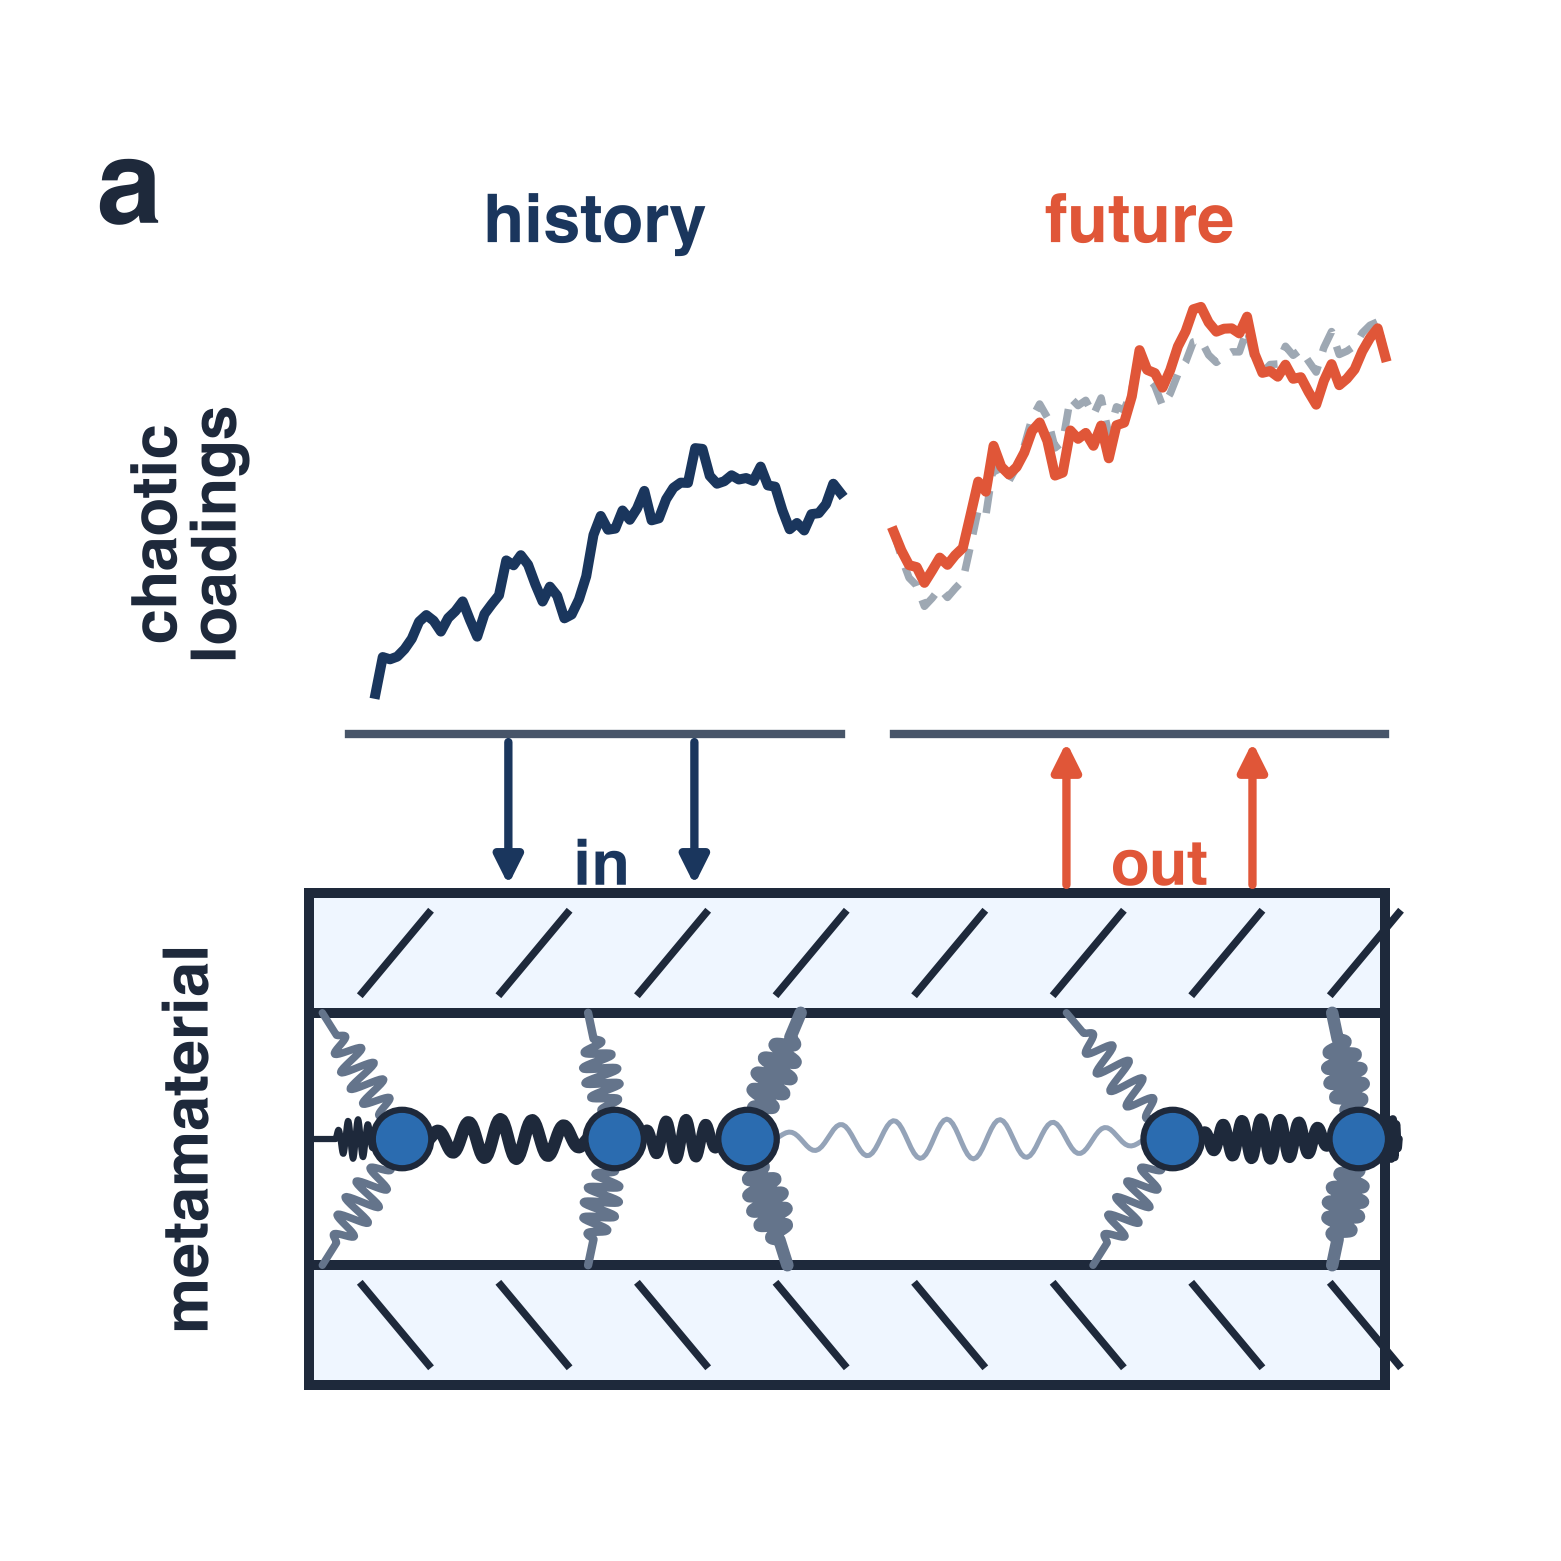

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Clean presentation typography
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=300)
ax.set_xlim(-0.08, 1.05)
ax.set_ylim(-0.08, 1.05)
ax.set_aspect("equal")
ax.axis("off")

# -------------------------------------------------------------
# Color Palette (Theme A: Navy, Coral & Slate)
# -------------------------------------------------------------
# C_HIST = "#1A365D"  # Deep Academic Navy (history)
# C_FUT = "#E05638"  # Warm Coral (future)
# C_DASH = "#94A3B8"  # Muted Slate for the dashed past/continuation
# C_NODE = "#2B6CB0"  # Mid-tone Blue
# C_FRAME = "#2D3748"  # Dark Charcoal borders
# C_PLATE = "#EDF2F7"  # Soft slate boundary fill
# C_AXIS = "#4A5568"  # Subdued axis lines
# C_SPRING = "#334155"  # Spring steel color

C_BLUE_DARK = "#1E40AF"  # Deep Royal Blue (history signal & 'in')
C_BLUE_NODE = "#2563EB"  # True Blue (metamaterial nodes)
C_BLUE_LIGHT = "#93C5FD"  # Soft Ice Blue (reference / dashed trajectory)

C_ORANGE_MAIN = "#EA580C"  # Vibrant Orange (future signal & 'out')
C_ORANGE_ACC = "#F97316"  # Bright Orange accent

C_FRAME = "#1E293B"  # Deep Charcoal / Navy frame
C_PLATE = "#EFF6FF"  # Ice-tinted boundary fill
C_AXIS = "#475569"  # Neutral Slate axis lines
C_SPRING = "#334155"  # Steel spring color
C_SPRING_DIM = "#94A3B8"  # Muted connector spring color


# -------------------------------------------------------------
# 1. Smooth Coiled Spring Function
# -------------------------------------------------------------
def draw_spring(ax, p1, p2, num_coils=5, width=0.015, lw=1.8, color=C_SPRING, zorder=3):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    dist = np.linalg.norm(p2 - p1)
    if dist == 0:
        return
    dir_vec = (p2 - p1) / dist
    norm_vec = np.array([-dir_vec[1], dir_vec[0]])

    lead = 0.02
    spring_len = max(0.01, dist - 2 * lead)
    s = np.linspace(0, spring_len, num_coils * 18)
    phase = 2 * np.pi * num_coils * (s / spring_len)
    envelope = np.sin(np.pi * s / spring_len) ** 0.5
    offset = width * np.sin(phase) * envelope

    x = [p1[0], (p1 + dir_vec * lead)[0]]
    y = [p1[1], (p1 + dir_vec * lead)[1]]
    for si, off in zip(s, offset):
        pt = p1 + dir_vec * (lead + si) + norm_vec * off
        x.append(pt[0])
        y.append(pt[1])
    x.extend([(p2 - dir_vec * lead)[0], p2[0]])
    y.extend([(p2 - dir_vec * lead)[1], p2[1]])
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# -------------------------------------------------------------
# 2. Chaotic Loading Waves with Dashed Reference
# -------------------------------------------------------------
np.random.seed(18)
n_pts = 65

# Generate a continuous smooth random trajectory across the full timeline
raw_walk = np.cumsum(np.random.randn(n_pts * 2))
raw_walk = (raw_walk - np.min(raw_walk)) / (np.max(raw_walk) - np.min(raw_walk))
signal_y = 0.55 + raw_walk * 0.28

x_hist = np.linspace(0.18, 0.53, n_pts)
x_fut = np.linspace(0.57, 0.94, n_pts)

y_hist = signal_y[:n_pts]
y_true_continuation = signal_y[n_pts:]  # Actual trajectory extended from the past
# Modeled/predicted future with subtle physical divergence
y_fut = y_true_continuation + 0.025 * np.sin(np.linspace(0, 4 * np.pi, n_pts))

# (A) History baseline & curve
ax.plot([0.16, 0.53], [0.52, 0.52], color=C_AXIS, lw=2.0)
ax.plot(x_hist, y_hist, color=C_HIST, lw=2.4, zorder=4)
ax.text(0.345, 0.89, "history", color=C_HIST, fontsize=16, weight="bold", ha="center")

# (B) Future baseline & curves
ax.plot([0.57, 0.94], [0.52, 0.52], color=C_AXIS, lw=2.0)

# Dashed line showing ground truth continuation of the past
ax.plot(
    x_fut,
    y_true_continuation,
    color=C_DASH,
    lw=1.8,
    linestyle="--",
    dashes=(3, 2),
    label="actual past trajectory",
    zorder=3,
)

# Future predicted curve overlay
ax.plot(x_fut, y_fut, color=C_FUT, lw=2.4, label="predicted", zorder=4)
ax.text(0.755, 0.89, "future", color=C_FUT, fontsize=16, weight="bold", ha="center")

# -------------------------------------------------------------
# 3. Transfer Arrows ("in" / "out")
# -------------------------------------------------------------
arrow_down = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color=C_HIST)
ax.annotate("", xy=(0.28, 0.40), xytext=(0.28, 0.52), arrowprops=arrow_down)
ax.annotate("", xy=(0.42, 0.40), xytext=(0.42, 0.52), arrowprops=arrow_down)
ax.text(
    0.35, 0.42, "in", color=C_HIST, fontsize=15, weight="bold", ha="center", va="center"
)

arrow_up = dict(arrowstyle="-|>", lw=2, mutation_scale=14, color=C_FUT)
ax.annotate("", xy=(0.70, 0.52), xytext=(0.70, 0.40), arrowprops=arrow_up)
ax.annotate("", xy=(0.84, 0.52), xytext=(0.84, 0.40), arrowprops=arrow_up)
ax.text(
    0.77, 0.42, "out", color=C_FUT, fontsize=15, weight="bold", ha="center", va="center"
)

# -------------------------------------------------------------
# 4. Metamaterial Housing & Rigid Boundary Plates
# -------------------------------------------------------------
box_x0, box_x1 = 0.13, 0.94
y_bot_low, y_bot_high = 0.03, 0.12
y_top_low, y_top_high = 0.31, 0.40

# Slate gray boundary plates
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_top_low),
        box_x1 - box_x0,
        y_top_high - y_top_low,
        facecolor=C_PLATE,
        edgecolor=C_FRAME,
        lw=2.4,
        zorder=2,
    )
)
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_bot_low),
        box_x1 - box_x0,
        y_bot_high - y_bot_low,
        facecolor=C_PLATE,
        edgecolor=C_FRAME,
        lw=2.4,
        zorder=2,
    )
)

# Outer vertical frame bounds
ax.plot([box_x0, box_x0], [y_bot_low, y_top_high], color=C_FRAME, lw=2.4, zorder=2)
ax.plot([box_x1, box_x1], [y_bot_low, y_top_high], color=C_FRAME, lw=2.4, zorder=2)

# Boundary slashes
for x_hatch in np.linspace(box_x0 + 0.04, box_x1 - 0.04, 8):
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_top_low + 0.015, y_top_high - 0.015],
        color=C_FRAME,
        lw=1.8,
        zorder=3,
    )
    ax.plot(
        [x_hatch, x_hatch + 0.05],
        [y_bot_high - 0.015, y_bot_low + 0.015],
        color=C_FRAME,
        lw=1.8,
        zorder=3,
    )

# -------------------------------------------------------------
# 5. Nodes and Spring Network
# -------------------------------------------------------------
nodes_x = [0.13, 0.20, 0.36, 0.46, 0.78, 0.92, 0.94]
y_mid = 0.215

# Diagonal boundary springs (Top & Bottom)
anchors = [
    (0.20, 0.14, 0.14, 1.8),
    (0.36, 0.34, 0.34, 2.0),
    (0.46, 0.50, 0.49, 3.0),
    (0.78, 0.70, 0.72, 1.8),
    (0.92, 0.90, 0.90, 3.0),
]

for nx, tx, bx, w in anchors:
    draw_spring(
        ax,
        (nx, y_mid),
        (tx, y_top_low),
        num_coils=5,
        width=0.013,
        lw=w,
        color="#64748B",
    )
    draw_spring(
        ax,
        (nx, y_mid),
        (bx, y_bot_high),
        num_coils=5,
        width=0.013,
        lw=w,
        color="#64748B",
    )

# Horizontal coupling springs
h_springs = [
    (nodes_x[0], nodes_x[1], 1.5, 4, C_FRAME),
    (nodes_x[1], nodes_x[2], 3.0, 5, C_FRAME),
    (nodes_x[2], nodes_x[3], 2.6, 4, C_FRAME),
    (nodes_x[3], nodes_x[4], 1.2, 7, "#94A3B8"),
    (nodes_x[4], nodes_x[5], 2.8, 7, C_FRAME),
    (nodes_x[5], nodes_x[6], 2.0, 4, C_FRAME),
]

for x1, x2, lw, coils, col in h_springs:
    draw_spring(
        ax, (x1, y_mid), (x2, y_mid), num_coils=coils, width=0.015, lw=lw, color=col
    )

# Central Blue Nodes
for x in nodes_x[1:-1]:
    circle = plt.Circle(
        (x, y_mid), 0.022, facecolor=C_NODE, edgecolor=C_FRAME, lw=1.5, zorder=6
    )
    ax.add_patch(circle)

# -------------------------------------------------------------
# 6. Panel Letter & Rotated Side Labels
# -------------------------------------------------------------
ax.text(
    -0.03, 0.93, "a", fontsize=28, weight="bold", color=C_FRAME, va="center", ha="left"
)

ax.text(
    0.04,
    0.67,
    "chaotic\nloadings",
    fontsize=15,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
    multialignment="center",
)

ax.text(
    0.04,
    0.215,
    "metamaterial",
    fontsize=15,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
)

# Export
plt.savefig("metamaterial_with_dashed_past.svg", bbox_inches="tight", transparent=True)
plt.savefig("metamaterial_with_dashed_past.png", bbox_inches="tight", dpi=300)
plt.show()

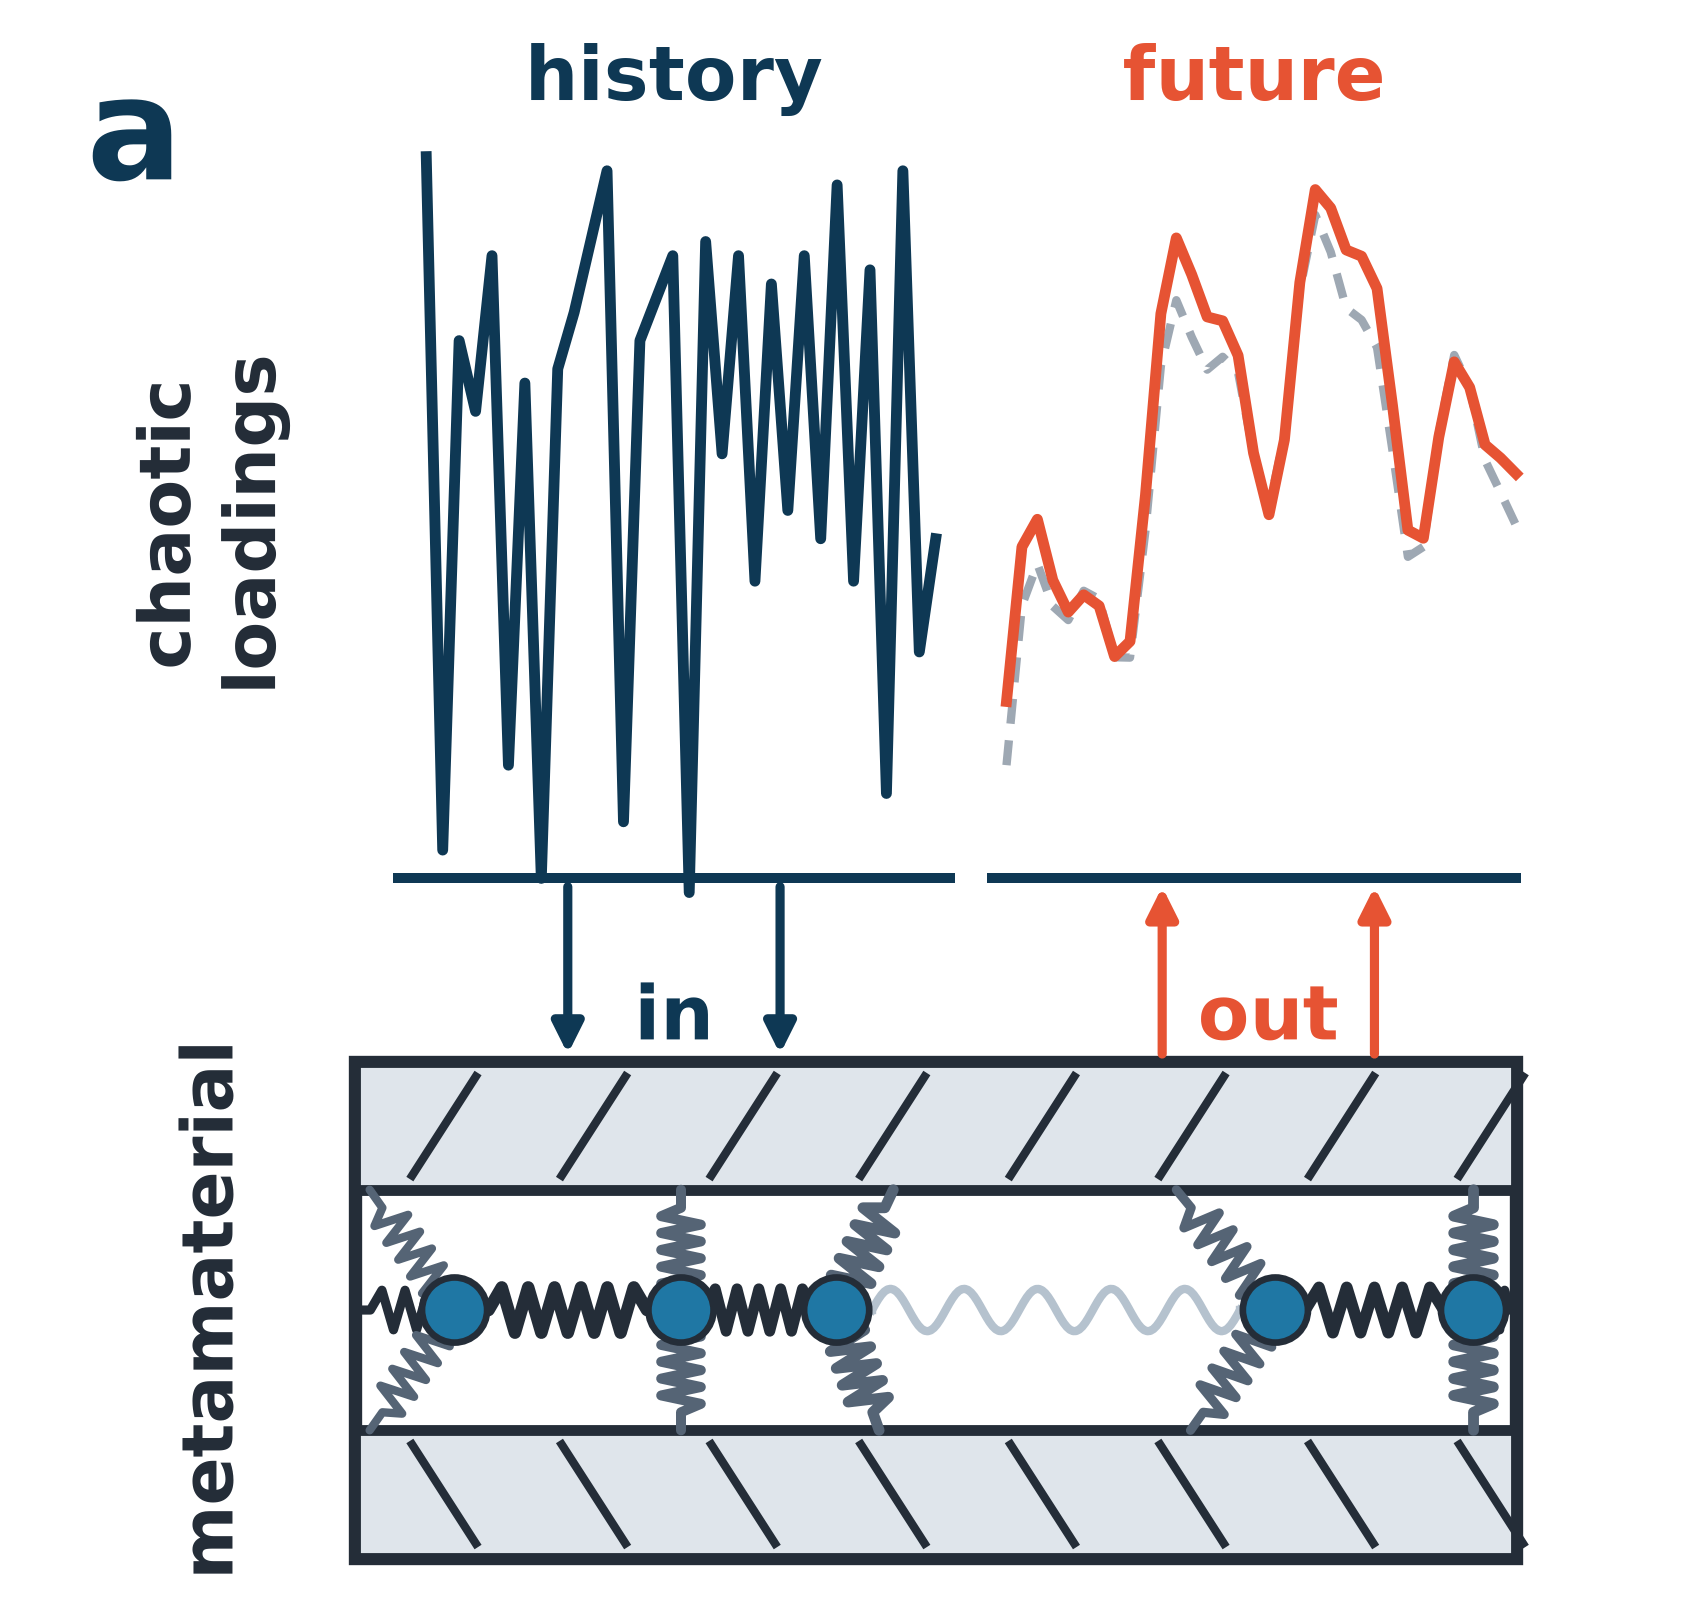

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Clean, modern sans-serif
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(7, 6.8), dpi=300)
ax.set_xlim(-0.10, 1.05)
ax.set_ylim(-0.06, 1.04)
ax.set_aspect("equal")
ax.axis("off")

# -------------------------------------------------------------
# Color Palette
# -------------------------------------------------------------
C_DARK_BLUE = "#0e3854"  # History wave, "in" text, "a", arrows
C_ORANGE = "#e65333"  # Future wave, "out" text, arrows
C_DASH = "#9ea8b3"  # Dashed ground truth line
C_NODE = "#1f77a4"  # Teal-blue masses
C_FRAME = "#242d38"  # Thick boundaries & text labels
C_PLATE_BG = "#dfe5eb"  # Plates fill
C_SPRING_DARK = "#242d38"  # Stiff / dark springs
C_SPRING_MID = "#556475"  # Vertical anchor springs
C_SPRING_LIGHT = "#b5c2ce"  # Soft connecting central spring


# -------------------------------------------------------------
# 1. Engineering Spring Path Generator (True Zig-zag / Coil)
# -------------------------------------------------------------
def get_spring_pts(p1, p2, num_turns=6, width=0.016, lead_ratio=0.15):
    p1 = np.array(p1, dtype=float)
    p2 = np.array(p2, dtype=float)
    vec = p2 - p1
    dist = np.linalg.norm(vec)
    if dist == 0:
        return p1.reshape(1, 2)

    u = vec / dist
    n = np.array([-u[1], u[0]])

    lead = dist * lead_ratio
    active_len = dist - 2 * lead

    # Zig-zag alternating offsets
    t_vals = np.linspace(0, active_len, num_turns * 2 + 1)
    pts = [p1, p1 + u * lead]

    for i, t in enumerate(t_vals[1:-1], start=1):
        sign = 1 if (i % 2 == 1) else -1
        pt = p1 + u * (lead + t) + n * (sign * width)
        pts.append(pt)

    pts.append(p2 - u * lead)
    pts.append(p2)
    return np.array(pts)


def plot_spring(
    ax, p1, p2, num_turns=6, width=0.016, lw=2.2, color=C_SPRING_DARK, zorder=3
):
    pts = get_spring_pts(p1, p2, num_turns, width)
    ax.plot(
        pts[:, 0], pts[:, 1], color=color, lw=lw, solid_capstyle="round", zorder=zorder
    )


# -------------------------------------------------------------
# 2. Top Signals (History & Future)
# -------------------------------------------------------------
np.random.seed(105)

# History: High-amplitude rapid chaotic oscillations
n_hist = 32
x_hist = np.linspace(0.18, 0.54, n_hist)
y_hist_raw = [
    0.95,
    0.46,
    0.82,
    0.77,
    0.88,
    0.52,
    0.79,
    0.44,
    0.80,
    0.84,
    0.89,
    0.94,
    0.48,
    0.82,
    0.85,
    0.88,
    0.43,
    0.89,
    0.74,
    0.88,
    0.65,
    0.86,
    0.70,
    0.88,
    0.68,
    0.93,
    0.65,
    0.87,
    0.50,
    0.94,
    0.60,
    0.68,
]
y_hist = np.array(y_hist_raw)

# History plot & baseline
ax.plot([0.16, 0.55], [0.44, 0.44], color=C_DARK_BLUE, lw=2.4)
ax.plot(x_hist, y_hist, color=C_DARK_BLUE, lw=2.6, zorder=4)
ax.text(
    0.355, 0.99, "history", color=C_DARK_BLUE, fontsize=18, weight="bold", ha="center"
)

# Future: Upward trending chaotic wave with dashed past/truth line
n_fut = 34
x_fut = np.linspace(0.59, 0.95, n_fut)
t = np.linspace(0, 1, n_fut)
trend = 0.54 + 0.30 * np.sin(t * np.pi * 0.85)
noise = 0.08 * np.sin(t * 22) + 0.04 * np.sin(t * 45)
y_truth = trend + noise

# Solid future output line
y_pred = y_truth + 0.025 * np.cos(t * 18)

# Future plot & baseline
ax.plot([0.58, 0.95], [0.44, 0.44], color=C_DARK_BLUE, lw=2.4)
ax.plot(
    x_fut, y_truth - 0.02, color=C_DASH, lw=2.0, linestyle="--", dashes=(3, 2), zorder=3
)
ax.plot(x_fut, y_pred, color=C_ORANGE, lw=2.6, zorder=4)
ax.text(0.765, 0.99, "future", color=C_ORANGE, fontsize=18, weight="bold", ha="center")

# -------------------------------------------------------------
# 3. Transfer Arrows ("in" / "out")
# -------------------------------------------------------------
arrow_down = dict(arrowstyle="-|>", lw=2.2, mutation_scale=15, color=C_DARK_BLUE)
ax.annotate("", xy=(0.28, 0.31), xytext=(0.28, 0.44), arrowprops=arrow_down)
ax.annotate("", xy=(0.43, 0.31), xytext=(0.43, 0.44), arrowprops=arrow_down)
ax.text(
    0.355,
    0.34,
    "in",
    color=C_DARK_BLUE,
    fontsize=18,
    weight="bold",
    ha="center",
    va="center",
)

arrow_up = dict(arrowstyle="-|>", lw=2.2, mutation_scale=15, color=C_ORANGE)
ax.annotate("", xy=(0.70, 0.44), xytext=(0.70, 0.31), arrowprops=arrow_up)
ax.annotate("", xy=(0.85, 0.44), xytext=(0.85, 0.31), arrowprops=arrow_up)
ax.text(
    0.775,
    0.34,
    "out",
    color=C_ORANGE,
    fontsize=18,
    weight="bold",
    ha="center",
    va="center",
)

# -------------------------------------------------------------
# 4. Metamaterial Outer Housing Plates
# -------------------------------------------------------------
box_x0, box_x1 = 0.13, 0.95
y_bot_low, y_bot_high = -0.04, 0.05
y_top_low, y_top_high = 0.22, 0.31
y_mid = 0.135

# Outer Frame
ax.add_patch(
    patches.Rectangle(
        (box_x0, -0.04),
        box_x1 - box_x0,
        0.35,
        fill=False,
        edgecolor=C_FRAME,
        lw=3.2,
        zorder=1,
    )
)

# Top & bottom gray plate fills
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_top_low),
        box_x1 - box_x0,
        y_top_high - y_top_low,
        facecolor=C_PLATE_BG,
        edgecolor=C_FRAME,
        lw=2.6,
        zorder=2,
    )
)
ax.add_patch(
    patches.Rectangle(
        (box_x0, y_bot_low),
        box_x1 - box_x0,
        y_bot_high - y_bot_low,
        facecolor=C_PLATE_BG,
        edgecolor=C_FRAME,
        lw=2.6,
        zorder=2,
    )
)

# Diagonal hatching lines
for hx in np.linspace(box_x0 + 0.04, box_x1 - 0.04, 8):
    # Top plate hatches
    ax.plot(
        [hx, hx + 0.045],
        [y_top_low + 0.01, y_top_high - 0.01],
        color=C_FRAME,
        lw=2.0,
        zorder=3,
    )
    # Bottom plate hatches
    ax.plot(
        [hx, hx + 0.045],
        [y_bot_high - 0.01, y_bot_low + 0.01],
        color=C_FRAME,
        lw=2.0,
        zorder=3,
    )

# -------------------------------------------------------------
# 5. Nodes and Metamaterial Springs
# -------------------------------------------------------------
nodes_x = [0.20, 0.36, 0.47, 0.78, 0.92]

# Left and Right Wall lead-in springs
plot_spring(
    ax,
    (box_x0, y_mid),
    (nodes_x[0], y_mid),
    num_turns=3,
    width=0.014,
    lw=2.2,
    color=C_SPRING_DARK,
)
plot_spring(
    ax,
    (nodes_x[-1], y_mid),
    (box_x1, y_mid),
    num_turns=3,
    width=0.014,
    lw=2.2,
    color=C_SPRING_DARK,
)

# Diagonal / Vertical Boundary Anchoring Springs
# Node 0 (corner anchors)
plot_spring(
    ax,
    (nodes_x[0], y_mid),
    (box_x0 + 0.01, y_top_low),
    num_turns=5,
    width=0.012,
    lw=2.0,
    color=C_SPRING_MID,
)
plot_spring(
    ax,
    (nodes_x[0], y_mid),
    (box_x0 + 0.01, y_bot_high),
    num_turns=5,
    width=0.012,
    lw=2.0,
    color=C_SPRING_MID,
)

# Node 1 (straight vertical anchors)
plot_spring(
    ax,
    (nodes_x[1], y_mid),
    (nodes_x[1], y_top_low),
    num_turns=5,
    width=0.014,
    lw=2.4,
    color=C_SPRING_MID,
)
plot_spring(
    ax,
    (nodes_x[1], y_mid),
    (nodes_x[1], y_bot_high),
    num_turns=5,
    width=0.014,
    lw=2.4,
    color=C_SPRING_MID,
)

# Node 2 (angled vertical anchors)
plot_spring(
    ax,
    (nodes_x[2], y_mid),
    (nodes_x[2] + 0.04, y_top_low),
    num_turns=5,
    width=0.014,
    lw=2.6,
    color=C_SPRING_MID,
)
plot_spring(
    ax,
    (nodes_x[2], y_mid),
    (nodes_x[2] + 0.03, y_bot_high),
    num_turns=5,
    width=0.014,
    lw=2.6,
    color=C_SPRING_MID,
)

# Node 3 (angled truss anchors)
plot_spring(
    ax,
    (nodes_x[3], y_mid),
    (nodes_x[3] - 0.07, y_top_low),
    num_turns=5,
    width=0.013,
    lw=2.2,
    color=C_SPRING_MID,
)
plot_spring(
    ax,
    (nodes_x[3], y_mid),
    (nodes_x[3] - 0.06, y_bot_high),
    num_turns=5,
    width=0.013,
    lw=2.2,
    color=C_SPRING_MID,
)

# Node 4 (straight vertical anchors)
plot_spring(
    ax,
    (nodes_x[4], y_mid),
    (nodes_x[4], y_top_low),
    num_turns=5,
    width=0.014,
    lw=2.6,
    color=C_SPRING_MID,
)
plot_spring(
    ax,
    (nodes_x[4], y_mid),
    (nodes_x[4], y_bot_high),
    num_turns=5,
    width=0.014,
    lw=2.6,
    color=C_SPRING_MID,
)

# Horizontal Inter-Node Coupling Springs
# Node 0 -> Node 1 (Stiff, dense dark coils)
plot_spring(
    ax,
    (nodes_x[0], y_mid),
    (nodes_x[1], y_mid),
    num_turns=6,
    width=0.016,
    lw=3.0,
    color=C_SPRING_DARK,
)

# Node 1 -> Node 2 (Short tight coils)
plot_spring(
    ax,
    (nodes_x[1], y_mid),
    (nodes_x[2], y_mid),
    num_turns=5,
    width=0.015,
    lw=2.6,
    color=C_SPRING_DARK,
)

# Node 2 -> Node 3 (Long, soft/flexible sine wave spring)
x_soft = np.linspace(nodes_x[2] + 0.025, nodes_x[3] - 0.025, 120)
y_soft = y_mid + 0.015 * np.sin(np.linspace(0, 5 * 2 * np.pi, len(x_soft)))
ax.plot(x_soft, y_soft, color=C_SPRING_LIGHT, lw=2.0, zorder=3)
ax.plot(
    [nodes_x[2], x_soft[0]], [y_mid, y_soft[0]], color=C_SPRING_LIGHT, lw=2.0, zorder=3
)
ax.plot(
    [x_soft[-1], nodes_x[3]],
    [y_soft[-1], y_mid],
    color=C_SPRING_LIGHT,
    lw=2.0,
    zorder=3,
)

# Node 3 -> Node 4 (Stiff dark coils)
plot_spring(
    ax,
    (nodes_x[3], y_mid),
    (nodes_x[4], y_mid),
    num_turns=5,
    width=0.016,
    lw=2.8,
    color=C_SPRING_DARK,
)

# Blue Mass Nodes
for xn in nodes_x:
    circle = plt.Circle(
        (xn, y_mid), 0.023, facecolor=C_NODE, edgecolor=C_FRAME, lw=1.6, zorder=6
    )
    ax.add_patch(circle)

# -------------------------------------------------------------
# 6. Letter Label & Rotated Side Titles
# -------------------------------------------------------------
ax.text(
    -0.06, 1.01, "a", fontsize=34, weight="bold", color=C_DARK_BLUE, va="top", ha="left"
)

ax.text(
    0.03,
    0.69,
    "chaotic\nloadings",
    fontsize=17,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
    multialignment="center",
)

ax.text(
    0.03,
    0.135,
    "metamaterial",
    fontsize=17,
    weight="bold",
    color=C_FRAME,
    rotation=90,
    va="center",
    ha="center",
)

# Export high-res raster & vector directly for Keynote
plt.savefig("metamaterial_final.svg", bbox_inches="tight", transparent=True)
plt.savefig("metamaterial_final.png", bbox_inches="tight", dpi=300)
plt.show()

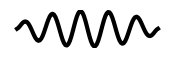

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(2, 0.5))
x = np.linspace(0, 1, 100)
y = 0.5 * np.sin(x * 10 * np.pi) * (np.sin(np.pi * x) ** 0.5)
ax.plot(x, y, color="black", lw=3)
ax.axis("off")
plt.savefig("single_spring.svg", transparent=True, bbox_inches="tight")

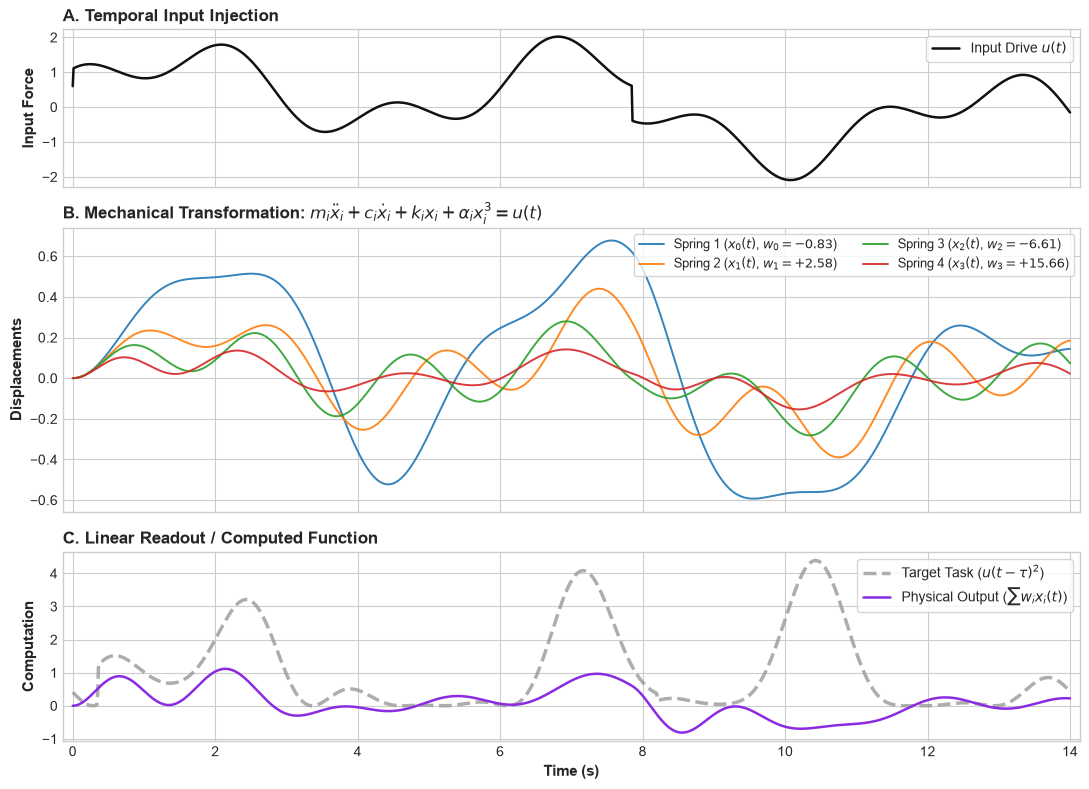

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# ------------------------------------------------------------------
# 1. Generate Input Time Series u(t)
# ------------------------------------------------------------------
t = np.linspace(0, 14, 1200)
# A driving signal with mixed frequencies and step variations
u = np.sin(1.1 * t) + 0.6 * np.cos(2.8 * t) + 0.5 * np.sign(np.sin(0.4 * t))

# ------------------------------------------------------------------
# 2. Simulate Spring Reservoir Dynamics
# Equation: x'' + 2*zeta*w*x' + w^2*x + alpha*x^3 = u(t)
# ------------------------------------------------------------------
n_springs = 4
omegas = np.linspace(1.8, 4.2, n_springs)  # Natural frequencies
zetas = np.array([0.15, 0.20, 0.12, 0.18])  # Damping ratios
alphas = np.array([0.40, 0.75, 0.30, 0.90])  # Spring cubic nonlinearities

responses = []
for w_n, z, a in zip(omegas, zetas, alphas):

    def spring_ode(state, t_val):
        x, v = state
        u_t = np.interp(t_val, t, u)
        dxdt = v
        dvdt = u_t - 2 * z * w_n * v - (w_n**2) * x - a * (x**3)
        return [dxdt, dvdt]

    sol = odeint(spring_ode, [0.0, 0.0], t)
    responses.append(sol[:, 0])

X = np.column_stack(responses)  # Reservoir states: [T x N]

# ------------------------------------------------------------------
# 3. Readout Layer: Compute Target via Ridge Regression
# Target task: Squared delayed signal u(t - tau)^2
# ------------------------------------------------------------------
tau_samples = 30
target = np.roll(u, tau_samples) ** 2

# Train linear readout weights: w = (X^T X + lambda I)^-1 X^T target
ridge_reg = 1e-3
w = np.linalg.pinv(X.T @ X + ridge_reg * np.eye(n_springs)) @ X.T @ target
computed_output = X @ w

# ------------------------------------------------------------------
# 4. Multi-Panel Visualization
# ------------------------------------------------------------------
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, axes = plt.subplots(
    3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.8, 1.2]}
)

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

# Panel 1: Input Time Series
axes[0].plot(t, u, color="#111111", lw=1.8, label=r"Input Drive $u(t)$")
axes[0].set_ylabel("Input Force", fontsize=11, fontweight="bold")
axes[0].set_title(
    "A. Temporal Input Injection", loc="left", fontsize=12, fontweight="bold"
)
axes[0].legend(loc="upper right", frameon=True)

# Panel 2: Physical Spring Displacements (Reservoir State)
for i in range(n_springs):
    axes[1].plot(
        t,
        X[:, i],
        color=colors[i],
        lw=1.4,
        alpha=0.9,
        label=rf"Spring {i+1} ($x_{i}(t)$, $w_{i}={w[i]:+.2f}$)",
    )
axes[1].set_ylabel("Displacements", fontsize=11, fontweight="bold")
axes[1].set_title(
    r"B. Mechanical Transformation: $m_i \ddot{x}_i + c_i \dot{x}_i + k_i x_i + \alpha_i x_i^3 = u(t)$",
    loc="left",
    fontsize=12,
    fontweight="bold",
)
axes[1].legend(loc="upper right", ncol=2, frameon=True, fontsize=9)

# Panel 3: Computed Readout vs Ground Truth Target
axes[2].plot(
    t,
    target,
    color="#999999",
    lw=2.5,
    ls="--",
    alpha=0.8,
    label=r"Target Task ($u(t-\tau)^2$)",
)
axes[2].plot(
    t,
    computed_output,
    color="#8a2be2",
    lw=1.8,
    label=r"Physical Output ($\sum w_i x_i(t)$)",
)
axes[2].set_ylabel("Computation", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Time (s)", fontsize=11, fontweight="bold")
axes[2].set_title(
    "C. Linear Readout / Computed Function", loc="left", fontsize=12, fontweight="bold"
)
axes[2].legend(loc="upper right", frameon=True)

# Add stage progression arrows on the side
for ax in axes:
    ax.margins(x=0.01)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

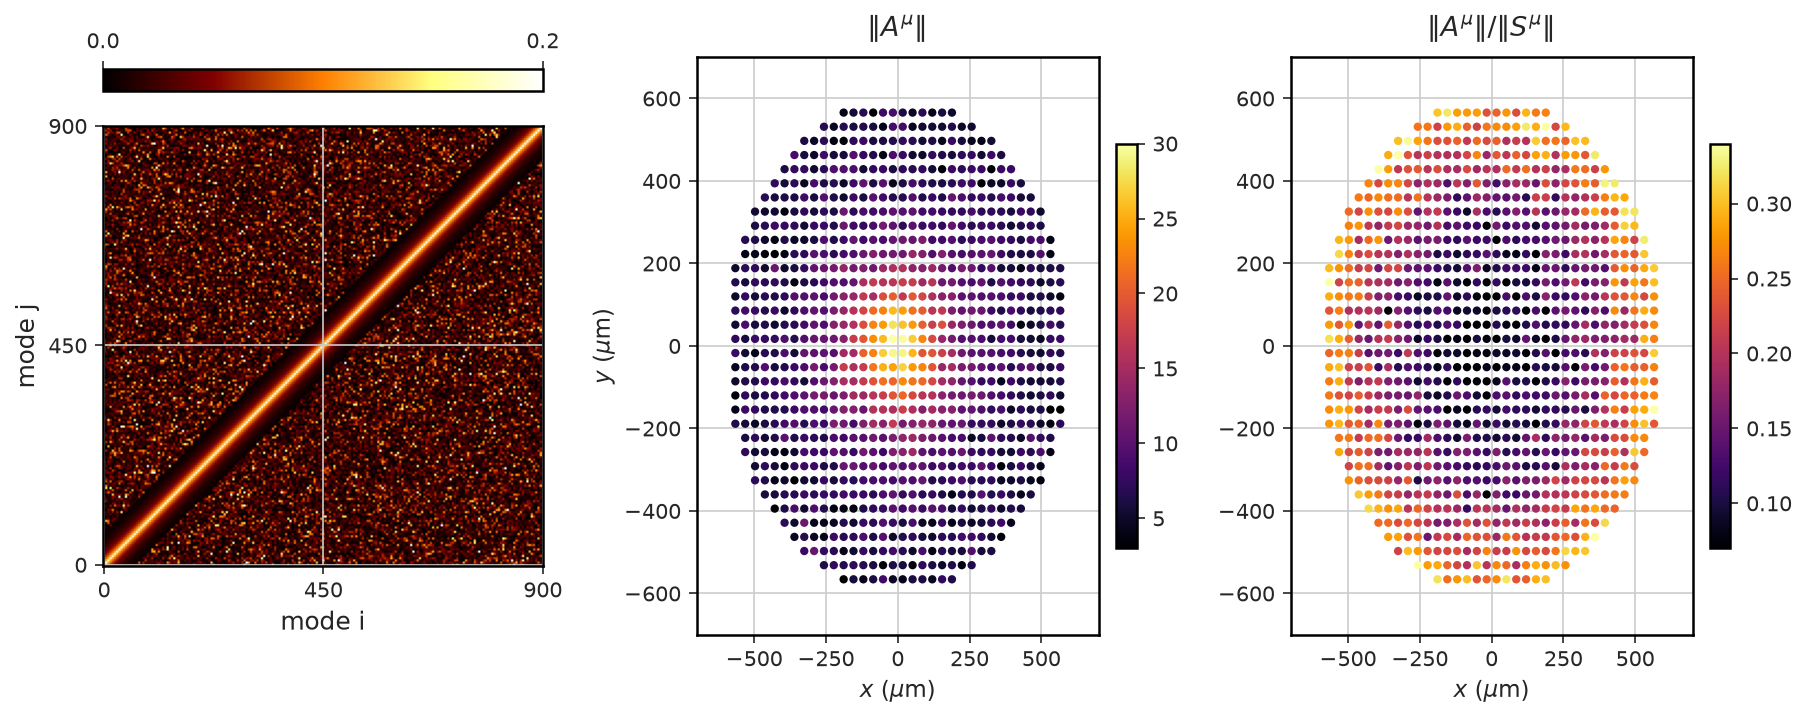

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Global Academic / Nature-Style Formatting
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
        "axes.edgecolor": "black",
        "axes.linewidth": 1.2,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 4,
        "ytick.major.size": 4,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)

fig = plt.figure(figsize=(14, 5), dpi=150)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1], wspace=0.35)

# -------------------------------------------------------------------------
# Plot 1: Heatmap (afmhot / copper style)
# -------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0])
data_matrix = np.random.exponential(scale=0.03, size=(200, 200))
# Add diagonal ridge
np.fill_diagonal(data_matrix, np.linspace(0.18, 0.22, 200))
for k in range(1, 15):
    band = np.exp(-k / 4.0) * 0.15
    np.fill_diagonal(data_matrix[k:], band)
    np.fill_diagonal(data_matrix[:, k:], band)

# 'afmhot' matches the black-brown-gold-white gradient exactly
im1 = ax1.imshow(data_matrix, cmap="afmhot", origin="lower", vmin=0.0, vmax=0.20)
ax1.set_xlabel("mode i", fontsize=12)
ax1.set_ylabel("mode j", fontsize=12)
ax1.set_xticks([0, 100, 200])
ax1.set_xticklabels(["0", "450", "900"])
ax1.set_yticks([0, 100, 200])
ax1.set_yticklabels(["0", "450", "900"])

# Top horizontal colorbar
cax1 = ax1.inset_axes([0.0, 1.08, 1.0, 0.05])
cb1 = fig.colorbar(im1, cax=cax1, orientation="horizontal")
cb1.set_ticks([0.0, 0.2])
cax1.xaxis.set_ticks_position("top")

# -------------------------------------------------------------------------
# Plot 2 & 3: Hexagonal Lattice with 'inferno' Colormap
# -------------------------------------------------------------------------
# Generate a disk of lattice points
r_max = 600
coords = []
for x in np.linspace(-600, 600, 36):
    for y in np.linspace(-600, 600, 36):
        if x**2 + y**2 <= r_max**2:
            coords.append((x, y))
coords = np.array(coords)

# Distance-based field with noise
dist = np.sqrt(coords[:, 0] ** 2 + coords[:, 1] ** 2)
vals_center = np.clip(
    30 * np.exp(-dist / 160) + np.random.normal(5, 1.5, len(coords)), 3, 30
)

# Plot 2 (Center Intensity)
ax2 = fig.add_subplot(gs[1])
sc2 = ax2.scatter(
    coords[:, 0],
    coords[:, 1],
    c=vals_center,
    cmap="inferno",
    s=16,
    edgecolors="none",
    vmin=3,
    vmax=30,
)
ax2.set_title(r"$\|A^\mu\|$", fontsize=13, pad=10)
ax2.set_xlabel(r"$x\ (\mu\mathrm{m})$", fontsize=11)
ax2.set_ylabel(r"$y\ (\mu\mathrm{m})$", fontsize=11)
ax2.set_xlim(-700, 700)
ax2.set_ylim(-700, 700)
fig.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)

# Plot 3 (Periphery / Ratio Intensity)
vals_ratio = np.clip(
    0.08 + 0.22 * (dist / r_max) ** 2 + np.random.normal(0, 0.03, len(coords)),
    0.07,
    0.35,
)

ax3 = fig.add_subplot(gs[2])
sc3 = ax3.scatter(
    coords[:, 0],
    coords[:, 1],
    c=vals_ratio,
    cmap="inferno",
    s=16,
    edgecolors="none",
    vmin=0.07,
    vmax=0.34,
)
ax3.set_title(r"$\|A^\mu\| / \|S^\mu\|$", fontsize=13, pad=10)
ax3.set_xlabel(r"$x\ (\mu\mathrm{m})$", fontsize=11)
ax3.set_xlim(-700, 700)
ax3.set_ylim(-700, 700)
fig.colorbar(sc3, ax=ax3, fraction=0.046, pad=0.04)

plt.show()

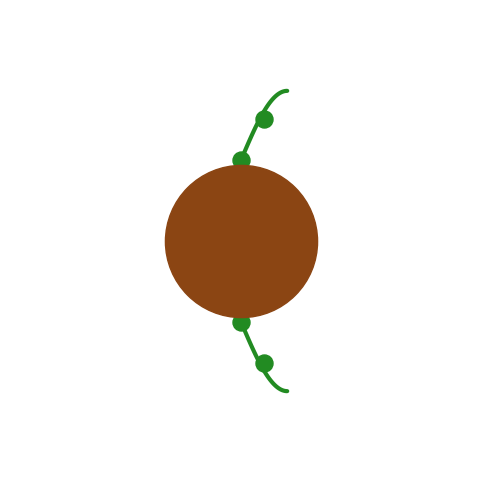

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Create the figure and axis
fig, ax = plt.subplots(figsize=(6, 6))

# 1. Draw the brown ball in the middle (center at 0,0)
# 'saddlebrown' or 'sienna' give a clean brown color.
# marker='o' creates a circle, and s setting controls the size.
ax.scatter(0, 0, color="saddlebrown", s=12000, zorder=2)

# 2. Draw the top sprig (green stem and leaves)
# Linspace creates smooth curves for the sprig stems
x_top = np.linspace(-0.2, 0.2, 100)
y_top = 0.35 + 0.3 * np.sin(x_top * np.pi * 2.5)  # Curved stem
ax.plot(x_top, y_top, color="forestgreen", linewidth=3, zorder=1)
# Small leaf-like points along the stem
ax.scatter([-0.1, 0, 0.1], [0.17, 0.35, 0.53], color="forestgreen", s=150, zorder=1)

# 3. Draw the bottom sprig (mirrored)
x_bot = np.linspace(-0.2, 0.2, 100)
y_bot = -0.35 - 0.3 * np.sin(x_bot * np.pi * 2.5)  # Curved stem
ax.plot(x_bot, y_bot, color="forestgreen", linewidth=3, zorder=1)
ax.scatter([-0.1, 0, 0.1], [-0.17, -0.35, -0.53], color="forestgreen", s=150, zorder=1)

# Clean up the plot layout
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_aspect("equal")  # Ensures the ball stays perfectly round
ax.axis("off")  # Hides the grid and boundary box

# Display the plot
plt.show()

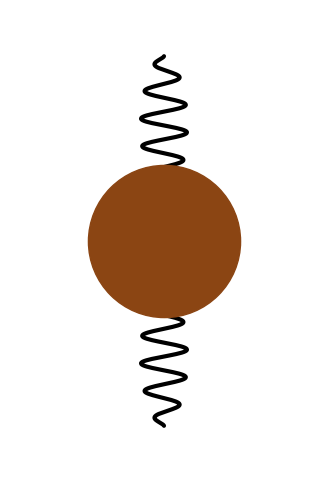

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Create a square canvas to handle the vertical layout cleanly
fig, ax = plt.subplots(figsize=(6, 6))

# 1. Draw the brown ball in the middle (centered at 0,0)
# zorder=2 places it on top of the springs so the start points hide behind it cleanly
ax.scatter(0, 0, color="saddlebrown", s=12000, zorder=2)

# ---- TOP SPRING ----
# Generate 200 points tracking from the edge of the ball (y=0.3) to the top peak (y=1.2)
y_top = np.linspace(0.3, 1.2, 200)
# u_top is the normalized position tracking 0 to 1 along the spring length
u_top = (y_top - 0.3) / (1.2 - 0.3)
# Your exact formula mapped to the X-axis variation
x_top = 0.15 * np.sin(u_top * 10 * np.pi) * (np.sin(np.pi * u_top) ** 0.5)

ax.plot(x_top, y_top, color="black", lw=3, zorder=1)


# ---- BOTTOM SPRING ----
# Mirroring the coordinates down the negative Y-axis
y_bot = np.linspace(-0.3, -1.2, 200)
u_bot = (y_bot + 0.3) / (-1.2 + 0.3)
x_bot = 0.15 * np.sin(u_bot * 10 * np.pi) * (np.sin(np.pi * u_bot) ** 0.5)

ax.plot(x_bot, y_bot, color="black", lw=3, zorder=1)


# Clean up canvas layout
ax.set_xlim(-1, 1)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")  # Keeps the ball circular and the spring uniform
ax.axis("off")  # Hides boundaries and ticks

# Optional: save out directly like your snippet
# plt.savefig("ball_with_springs.svg", transparent=True, bbox_inches="tight")
plt.show()

TypeError: 'float' object cannot be interpreted as an integer

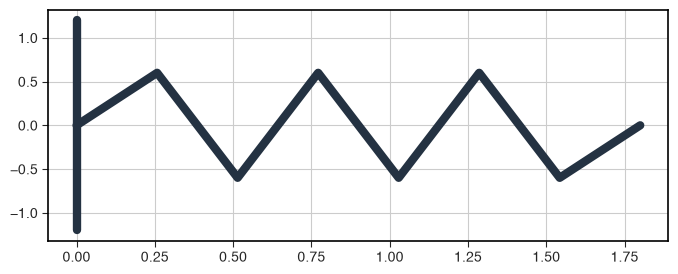

In [18]:
import matplotlib.pyplot as plt
import numpy as np


def generate_zigzag_spring(start_x, end_x, y_center, num_coils, max_width):
    """Generates the x and y coordinates for an angular zig-zag spring."""
    # Create alternating peak and trough targets for a clean zig-zag geometry
    num_points = 2 * num_coils + 2
    x_nodes = np.linspace(start_x, end_x, num_points)

    y_nodes = np.zeros(num_points) + y_center
    # Alternates between going up and down for the inner coils
    y_nodes[1:-1:2] += max_width / 2
    y_nodes[2:-1:2] -= max_width / 2

    return x_nodes, y_nodes


# Set up the figure layout (matching the horizontal widescreen style)
fig, ax = plt.subplots(figsize=(8, 3))

# Core styling parameters matching your reference image
line_color = "#243242"  # Deep dark slate/navy
ball_color = "#267bb4"  # Vibrant blue fill
line_width = 6  # Thick structural line weight

# 1. Draw the Fixed Anchor Wall on the left (x = 0)
ax.plot([0, 0], [-1.2, 1.2], color=line_color, lw=line_width, solid_capstyle="round")

# 2. Draw the main Left Spring (from wall to the center ball)
x_spring_L, y_spring_L = generate_zigzag_spring(
    start_x=0, end_x=1.8, y_center=0, num_coils=3, max_width=1.2
)
ax.plot(x_spring_L, y_spring_L, color=line_color, lw=line_width, solid_capstyle="round")

# 3. Draw the Right Spring Extension (trailing off the right side of the ball)
x_spring_R, y_spring_R = generate_zigzag_spring(
    start_x=1.8, end_x=2.8, y_center=0, num_coils=1.5, max_width=1.2
)
ax.plot(x_spring_R, y_spring_R, color=line_color, lw=line_width, solid_capstyle="round")

# 4. Draw the Blue Node (Centered at x = 1.8, y = 0)
# Utilizing a distinct edge and fill color to match the flat 2D diagram style
ax.scatter(
    1.8,
    0,
    facecolor=ball_color,
    edgecolor=line_color,
    linewidth=line_width,
    s=7000,
    zorder=3,
)

# Clean up layout and dimensions
ax.set_xlim(-0.2, 2.8)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.axis("off")

# Save and render
plt.savefig("horizontal_node_spring.svg", transparent=True, bbox_inches="tight")
plt.show()

<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
/var/folders/0r/235txxxd1p73wr0r5k9v6mqr0000gn/T/ipykernel_86658/1697199366.py:24: SyntaxWarning: invalid escape sequence '\p'
  ax1.plot([-y0, y0], [0, 0], "go", markersize=8, label="Stable States ($\pm y_0$)")


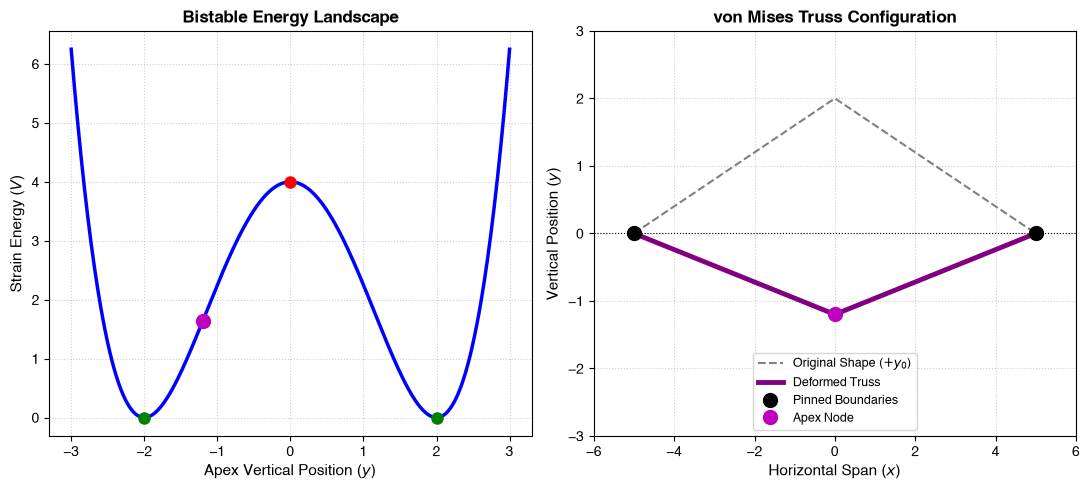

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define physical constants for the bistable well
y0 = 2.0  # Position of stable states (height of original truss)
k = 1.0  # Stiffness constant
L = 5.0  # Half-span width of the truss base

# Generate vertical displacement values (y-coordinates of the apex)
y_vals = np.linspace(-3.0, 3.0, 400)
# Quartic potential energy formula for a bistable system
energy = 0.25 * k * (y_vals**2 - y0**2) ** 2

# Choose a current state to highlight (e.g., snapped down slightly)
current_y = -1.2
current_energy = 0.25 * k * (current_y**2 - y0**2) ** 2

# 2. Set up the Matplotlib Figure (Energy Well + Truss Geometry)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

# --- Panel 1: The Bistable Potential Well ---
ax1.plot(y_vals, energy, "b-", lw=2.5, label="Potential Energy $V(y)$")
# Mark stable and unstable equilibrium points
ax1.plot([-y0, y0], [0, 0], "go", markersize=8, label="Stable States ($\pm y_0$)")
ax1.plot(0, 0.25 * k * y0**4, "ro", markersize=8, label="Unstable Apex ($y=0$)")
# Track current state
ax1.plot(current_y, current_energy, "mo", markersize=10, label="Current State")

ax1.set_title("Bistable Energy Landscape", fontsize=12, fontweight="bold")
ax1.set_xlabel("Apex Vertical Position ($y$)", fontsize=11)
ax1.set_ylabel("Strain Energy ($V$)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)

# --- Panel 2: von Mises Truss Schematic ---
# Ground support coordinates
left_pin = [-L, 0]
right_pin = [L, 0]

# Original undeformed truss layout (Dashed line)
ax2.plot(
    [left_pin[0], 0, right_pin[0]],
    [left_pin[1], y0, right_pin[1]],
    color="gray",
    linestyle="--",
    lw=1.5,
    label="Original Shape ($+y_0$)",
)

# Current deformed truss configuration (Solid line)
ax2.plot(
    [left_pin[0], 0, right_pin[0]],
    [left_pin[1], current_y, right_pin[1]],
    color="purple",
    lw=3.5,
    label="Deformed Truss",
)

# Draw pins/nodes as distinct markers
ax2.plot([-L, L], [0, 0], "ko", markersize=10, label="Pinned Boundaries")
ax2.plot(0, current_y, "mo", markersize=10, label="Apex Node")

ax2.set_title("von Mises Truss Configuration", fontsize=12, fontweight="bold")
ax2.set_xlabel("Horizontal Span ($x$)", fontsize=11)
ax2.set_ylabel("Vertical Position ($y$)", fontsize=11)
ax2.set_xlim(-L - 1, L + 1)
ax2.set_ylim(-y0 - 1, y0 + 1)
ax2.axhline(0, color="black", linewidth=0.8, linestyle=":")  # Baseline reference
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower center", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()